# Классификация банковских рисков в новостях

Исследование сравнивает Logistic Regression, LinearSVC и mDeBERTa на русскоязычных банковских новостях. Основная задача — обнаружить потенциальный риск, дополнительная — определить его категорию.

Проверяется, дают ли нейросеть и контекст новости полезное улучшение с учётом устойчивости, стоимости ошибок и затрат на обучение. Метрики, интервалы, графики и выводы формируются при выполнении.


## 1. Окружение и план

Ноутбук выполняется сверху вниз в Kaggle с CUDA GPU и Internet. `FULL` включает три бинарных входа × seed 42, 123, 2026 и три многоклассовых запуска: 12 обучений mDeBERTa. `CORE` — четыре обучения с seed 42 без оценки устойчивости. По умолчанию выбран `FULL`.

Эффективный batch фиксирован: 32 примера. Накопление градиентов рассчитывается по числу GPU. Сохранённый Output этого же эксперимента можно подключить через `RESUME_OUTPUT_SOURCE`: завершённые обучения проверяются и переиспользуются, прерванное обучение начинается заново. Несовместимые результаты не смешиваются.


In [1]:
import os, sys, subprocess, time
SESSION_STARTED_MONOTONIC = time.monotonic()
os.environ['USE_TF'] = '0'
os.environ['USE_FLAX'] = '0'
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'
PROFILE = 'FULL'
assert PROFILE in {'CORE', 'FULL'}
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
    '--disable-pip-version-check', 'transformers==4.57.3', 'accelerate>=1.0,<2',
    'sentencepiece>=0.2', 'safetensors>=0.4', 'scikit-learn==1.6.1',
    'scipy>=1.10', 'numpy>=1.24,<3', 'pandas>=2.0', 'matplotlib>=3.7', 'joblib', 'ipython'])
# Проверка импорта в отдельном процессе.
subprocess.check_call([sys.executable, '-c',
    'import torch; from transformers import Trainer, TrainingArguments; '
    'import accelerate; print("PyTorch", torch.__version__, "Accelerate", accelerate.__version__)'])


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
diffusers 0.42.0 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


PyTorch 2.11.0+cu130 Accelerate 1.15.0


0

In [2]:
from pathlib import Path
import gc, hashlib, importlib.metadata, inspect, json, random, re, shutil, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import torch
from IPython.display import display, Markdown
from scipy.stats import binomtest
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (average_precision_score, f1_score, precision_score, recall_score,
    precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay)
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding,
    Trainer, TrainingArguments, EarlyStoppingCallback, set_seed, DebertaV2Config,
    DebertaV2ForSequenceClassification)

assert torch.cuda.is_available(), 'Для полного исследования требуется GPU Kaggle.'
SEED = 42
SEEDS = [42, 123, 2026] if PROFILE == 'FULL' else [42]
LABELS = ['no_risk', 'cyber_risk', 'operational_risk', 'regulatory_risk']
MODEL_ID = 'microsoft/mdeberta-v3-base'
MODEL_REVISION = 'a0484667b22365f84929a935b5e50a51f71f159d'
OUTPUT = Path('/kaggle/working/bank_risk_diploma_final')
RESUME_OUTPUT_SOURCE = None  # Path('/kaggle/input/.../bank_risk_diploma_final')
OUTPUT.mkdir(parents=True, exist_ok=True)
BOOTSTRAP_REPS = 2000
PRECISION_TARGETS = [0.80, 0.90]
MIN_ALERTS = 10
DL_CONFIG = dict(epochs=6, learning_rate=2e-5, weight_decay=0.01, warmup_ratio=0.1,
    max_length=256, train_batch=4, eval_batch=8, patience=2, global_batch_size=32)
TRAIN_DEVICE_COUNT = torch.cuda.device_count()
assert int(os.environ.get('WORLD_SIZE','1')) == 1, 'Ноутбук рассчитан на обычное ядро Kaggle, без torchrun.'
assert DL_CONFIG['global_batch_size'] % (DL_CONFIG['train_batch']*TRAIN_DEVICE_COUNT) == 0, 'Число устройств должно позволять целый accumulation для global batch=32.'
DL_CONFIG['accumulation'] = DL_CONFIG['global_batch_size']//(DL_CONFIG['train_batch']*TRAIN_DEVICE_COUNT)
BINARY_INPUTS = ['text_without_title','text','bank_context']
TITLE_POLICY = 'exact title prefix; residual or missing title unchanged; strict shared evaluation subset'
PROTOCOL_VERSION = 'final-grouped-title-ablation-1'
CLASSICAL_C_GRID = [0.1, 1.0, 3.0]
ROLE_FOLDS = {'fit': [1, 3, 4], 'stop': [0], 'calibration': [2]}
SESSION_BUDGET_HOURS = 12.0  # Плановый бюджет сессии.
MAX_OUTPUT_GB = 20.0
DL_RUN_PLAN = [dict(task='binary', mode=mode, seed=seed,
    name=f'binary_mdeberta_{mode}_seed{seed}')
    for seed in SEEDS for mode in BINARY_INPUTS]
DL_RUN_PLAN += [dict(task='multiclass', mode='text', seed=seed,
    name=f'multiclass_mdeberta_text_seed{seed}') for seed in SEEDS]
assert len(DL_RUN_PLAN) == (12 if PROFILE == 'FULL' else 4)
set_seed(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.use_deterministic_algorithms(True, warn_only=True)

def file_sha256(path):
    with Path(path).open('rb') as stream:
        return hashlib.file_digest(stream,'sha256').hexdigest()

def clean_json(value):
    if isinstance(value, dict): return {str(k): clean_json(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)): return [clean_json(v) for v in value]
    if isinstance(value, (np.integer,)): return int(value)
    if isinstance(value, (float, np.floating)): return float(value) if np.isfinite(value) else None
    if isinstance(value, (np.bool_,)): return bool(value)
    if isinstance(value, Path): return str(value)
    return value

def save_json(name, value):
    path = OUTPUT / name; path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + '.partial')
    temporary.write_text(json.dumps(clean_json(value), ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')
    temporary.replace(path)

def save_csv(name, frame):
    path = OUTPUT / name; path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + '.partial')
    frame.to_csv(temporary, index=False)
    temporary.replace(path)

def save_fig(name):
    path = OUTPUT / 'figures' / name; path.parent.mkdir(parents=True, exist_ok=True)
    plt.tight_layout(); plt.savefig(path, dpi=140, bbox_inches='tight'); plt.show(); plt.close()

ENVIRONMENT = {name: importlib.metadata.version(name) for name in
    ['torch', 'transformers', 'accelerate', 'numpy', 'pandas', 'scikit-learn', 'scipy',
     'matplotlib', 'sentencepiece', 'safetensors', 'joblib']}
NOTEBOOK_BUILD_SHA256 = '1f0f0600340abcdf3ef3e97b9e8810c985b4a5963e95b0db5324d419f4c7b9b2'

def restore_final_output(source, expected_identity):
    """Восстановить совместимый сохранённый Output без перезаписи файлов."""
    if source is None or not str(source).strip():
        return dict(status='fresh', source=None)
    source_path = Path(source).expanduser()
    target_path = OUTPUT.expanduser()
    if any(p.is_symlink() or getattr(p, 'is_junction', lambda: False)()
           for p in [source_path, target_path]):
        raise RuntimeError('Путь восстановления не должен быть символической ссылкой.')
    source_path, target_path = source_path.resolve(), target_path.resolve()
    if source_path == target_path or source_path in target_path.parents or target_path in source_path.parents:
        raise RuntimeError('Исходный и рабочий Output должны находиться в отдельных каталогах.')
    if not source_path.is_dir():
        raise FileNotFoundError(f'Сохранённый Output не найден: {source_path}')
    expected_sha = hashlib.sha256(json.dumps(expected_identity,
        sort_keys=True, ensure_ascii=False).encode()).hexdigest()

    def inspect_output(root):
        entries = list(root.rglob('*'))
        for entry in [root, *entries]:
            if entry.is_symlink() or getattr(entry, 'is_junction', lambda: False)():
                raise RuntimeError(f'В Output обнаружена ссылка: {entry}')
            if not entry.is_file() and not entry.is_dir():
                raise RuntimeError(f'Необычный объект в Output: {entry}')
        manifest_path = root / 'experiment_manifest.json'
        if not manifest_path.is_file():
            raise RuntimeError(f'В Output отсутствует manifest: {root}')
        manifest = json.loads(manifest_path.read_text(encoding='utf-8'))
        if manifest.get('identity') != expected_identity or manifest.get('sha256') != expected_sha:
            raise RuntimeError(f'Output относится к другому протоколу или окружению: {root}')
        completed = list((root / 'runs').rglob('complete.json')) if (root / 'runs').is_dir() else []
        for marker in completed:
            completion = json.loads(marker.read_text(encoding='utf-8'))
            signature = completion.get('signature_sha256')
            if not isinstance(signature, str) or len(signature) != 64 or any(c not in '0123456789abcdef' for c in signature):
                raise RuntimeError(f'Некорректная подпись завершённого обучения: {marker}')
            identity_path = marker.parent / 'run_identity.json'
            if not identity_path.is_file():
                raise RuntimeError(f'Отсутствует идентификатор обучения: {identity_path}')
            identity = json.loads(identity_path.read_text(encoding='utf-8'))
            if identity.get('signature_sha256') != signature or not isinstance(identity.get('signature'), dict):
                raise RuntimeError(f'Не совпадает идентификатор обучения: {identity_path}')
            files = completion.get('files')
            record_relative = (marker.parent / 'record.json').relative_to(root).as_posix()
            if not isinstance(files, dict) or record_relative not in files:
                raise RuntimeError(f'Отсутствуют контрольные суммы результатов: {marker}')
            for relative, expected in files.items():
                relative_path = Path(relative)
                if relative_path.is_absolute() or relative_path.drive or '..' in relative_path.parts:
                    raise RuntimeError(f'Недопустимый путь результата: {relative}')
                artifact = (root / relative_path).resolve()
                if not artifact.is_relative_to(root) or not artifact.is_file():
                    raise RuntimeError(f'Результат отсутствует или находится вне Output: {relative}')
                if file_sha256(artifact) != expected:
                    raise RuntimeError(f'Повреждён сохранённый результат: {relative}')
        return dict(files=len([entry for entry in entries if entry.is_file()]),
            completed_runs=len(completed))

    source_report = inspect_output(source_path)
    if target_path.exists():
        if not target_path.is_dir():
            raise RuntimeError(f'Рабочий Output не является каталогом: {target_path}')
        if any(target_path.iterdir()):
            target_report = inspect_output(target_path)
            return dict(status='existing_compatible', source=str(source_path), **target_report)
    source_hashes = {p.relative_to(source_path).as_posix(): file_sha256(p)
        for p in source_path.rglob('*') if p.is_file()}
    target_path.parent.mkdir(parents=True, exist_ok=True)
    staging = target_path.with_name(target_path.name + '.restore-staging')
    suffix = 1
    while staging.exists():
        staging = target_path.with_name(target_path.name + f'.restore-staging-{suffix}')
        suffix += 1
    if staging.parent != target_path.parent or staging == source_path or source_path in staging.parents:
        raise RuntimeError('Некорректный временный каталог восстановления.')
    try:
        shutil.copytree(source_path, staging, symlinks=False)
        inspect_output(staging)
        copied_hashes = {p.relative_to(staging).as_posix(): file_sha256(p)
            for p in staging.rglob('*') if p.is_file()}
        if copied_hashes != source_hashes:
            raise RuntimeError('Не совпадают контрольные суммы скопированного Output.')
        if target_path.exists():
            if target_path.resolve() != OUTPUT.expanduser().resolve() or any(target_path.iterdir()):
                raise RuntimeError('Рабочий Output изменился во время восстановления.')
            target_path.rmdir()
        staging.replace(target_path)
    except Exception as error:
        raise RuntimeError(f'Восстановление остановлено; временные файлы сохранены: {staging}') from error
    return dict(status='restored', source=str(source_path), **source_report)

def claim_experiment_output(identity):
    # Проверка до записи результатов.
    identity = clean_json(identity)
    digest = hashlib.sha256(json.dumps(identity, sort_keys=True, ensure_ascii=False).encode()).hexdigest()
    restore_final_output(RESUME_OUTPUT_SOURCE, identity)
    manifest_path = OUTPUT / 'experiment_manifest.json'
    if manifest_path.exists():
        existing = json.loads(manifest_path.read_text(encoding='utf-8'))
        if existing.get('identity') != identity or existing.get('sha256') != digest:
            raise RuntimeError('Output содержит другой эксперимент. Сохраните его и выберите новый пустой OUTPUT; файлы не перезаписаны.')
    else:
        if any(OUTPUT.iterdir()):
            raise RuntimeError('Непустой Output без совместимого manifest. Требуется новый пустой каталог; файлы не перезаписаны.')
        save_json('experiment_manifest.json', dict(sha256=digest, identity=identity))
    save_json('experiment_status.json', dict(status='running', experiment_sha256=digest,
        note='Итоговые отчёты действительны только при status=complete.'))
    return digest

input_candidates = sorted(Path('/kaggle/input').rglob('bank_risk_dataset.csv'))
assert len(input_candidates) == 1, 'Требуется ровно один исходный bank_risk_dataset.csv'
input_sha = hashlib.sha256(input_candidates[0].read_bytes()).hexdigest()
assert input_sha == '52333a13e7fb6f6c4162486198fbf1d1ab368672a8974295995580a1924f67f3', 'Иная версия датасета'
experiment_identity = dict(schema=1, notebook_build_sha256=NOTEBOOK_BUILD_SHA256,
    protocol=PROTOCOL_VERSION, data_sha256=input_sha, role_folds=ROLE_FOLDS,
    splitter=dict(algorithm='StratifiedGroupKFold', folds=5, seed=SEED),
    profile=PROFILE, seeds=SEEDS, labels=LABELS, model=MODEL_ID, revision=MODEL_REVISION,
    dl=DL_CONFIG, binary_inputs=BINARY_INPUTS, title_policy=TITLE_POLICY, classical_C_grid=CLASSICAL_C_GRID, bootstrap_replicates=BOOTSTRAP_REPS,
    precision_targets=PRECISION_TARGETS, min_alerts=MIN_ALERTS, runs=DL_RUN_PLAN,
    environment=ENVIRONMENT, python=sys.version,
    hardware=dict(gpu=torch.cuda.get_device_name(0), devices=torch.cuda.device_count(),
        cuda=torch.version.cuda, bf16=torch.cuda.is_bf16_supported(), fp16=not torch.cuda.is_bf16_supported()))
EXPERIMENT_SHA = claim_experiment_output(experiment_identity)

save_json('environment.json', dict(packages=ENVIRONMENT, python=sys.version,
    gpu=torch.cuda.get_device_name(0), cuda=torch.version.cuda))
print('GPU:', torch.cuda.get_device_name(0), '| профиль:', PROFILE)


GPU: Tesla T4 | профиль: FULL


## 2. Данные

Датасет содержит 5 041 запись: train — 3 535, valid — 755, test — 751. Цели — наличие риска (`alert_flag`) и его категория (`risk_type_4cls`). Исходные метки, идентификаторы и разбиения сохраняются.

`found_risk_keywords` не используется из-за возможной связи с разметкой. Анализ текстовых признаков по классам проводится только на train.


In [3]:
sources = sorted(Path('/kaggle/input').rglob('bank_risk_dataset.csv'))
assert len(sources) == 1, f'Требуется один исходный CSV в Kaggle Input, найдено: {sources}'
DATA_PATH = sources[0]
DATA_SHA = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
assert DATA_SHA == '52333a13e7fb6f6c4162486198fbf1d1ab368672a8974295995580a1924f67f3', 'Неожиданная версия датасета'
df = pd.read_csv(DATA_PATH).copy()
required = {'sample_id', 'event_group_id', 'split', 'text_fragment', 'title', 'entity_norm',
            'alert_flag', 'risk_type_4cls', 'published_year', 'source'}
assert required.issubset(df.columns)
assert len(df) == 5041 and df.sample_id.is_unique
assert df[['sample_id', 'event_group_id', 'split', 'alert_flag', 'risk_type_4cls']].notna().all().all()
assert set(df.split) == {'train', 'valid', 'test'} and set(df.risk_type_4cls) == set(LABELS)
assert set(df.alert_flag) == {0, 1}
assert (df.alert_flag.eq(0) == df.risk_type_4cls.eq('no_risk')).all()
for col in ['text_fragment', 'title', 'entity_norm']:
    df[col] = df[col].fillna('').astype(str)
assert df.text_fragment.str.strip().ne('').all()
parts = {s: df[df.split.eq(s)].reset_index(drop=True) for s in ['train', 'valid', 'test']}
assert [len(parts[s]) for s in parts] == [3535, 755, 751]
for a, b in [('train', 'valid'), ('train', 'test'), ('valid', 'test')]:
    assert not set(parts[a].event_group_id) & set(parts[b].event_group_id), (a, b)
save_json('dataset.json', dict(sha256=DATA_SHA, rows=len(df), labels=LABELS))


## 3. Исследовательский анализ

Распределения классов, банков, источников, лет и длин текстов показывают состав и перекосы данных. Проверка повторов помогает оценить зависимость наблюдений. Высокое текстовое сходство отмечает возможный повтор; строки автоматически не удаляются.


,news,groups
split,,
train,3535,3479
valid,755,745
test,751,746


risk_type_4cls,no_risk,cyber_risk,operational_risk,regulatory_risk
split,,,,
train,3359,74,67,35
valid,715,20,13,7
test,713,17,17,4


risk_type_4cls,no_risk,cyber_risk,operational_risk,regulatory_risk
split,,,,
train,0.9502,0.0209,0.0190,0.0099
valid,0.9470,0.0265,0.0172,0.0093
test,0.9494,0.0226,0.0226,0.0053


Всего новостей    5041
Банков              15
Групп событий     4970
Первый год        1999
Последний год     2020
dtype: int64

,source,news
0,buriy,1590
1,ods_tass,1450
2,lenta,1017
3,telegram_contest,584
4,taiga_fontanka,400


risk_type_4cls,no_risk,cyber_risk,operational_risk,regulatory_risk
entity_norm,,,,
Qiwi,5,0,0,0
Альфа-Банк,241,8,12,1
Банк Открытие,91,1,2,0
Банк Санкт-Петербург,6,0,0,1
ВТБ,1991,31,9,13
Газпромбанк,269,0,0,6
МТС Банк,4,0,0,0
Почта Банк,25,2,0,0
Промсвязьбанк,139,4,0,1


risk_type_4cls,no_risk,cyber_risk,operational_risk,regulatory_risk
published_year,,,,
1999,2,0,0,0
2000,1,0,0,0
2001,1,0,0,0
2002,7,0,0,0
2003,5,0,0,0
2004,12,0,0,0
2005,13,0,0,0
2006,17,1,0,0
2007,55,0,0,1


Доля крупнейшего банка: 40.5%; доля наиболее представленного года: 27.7%.


characters                                              \
                      count        mean         std   min    10%    25%   
risk_type_4cls                                                            
cyber_risk            111.0  442.549550  206.143981  96.0  204.0  323.0   
no_risk              4787.0  561.529141  220.125646  65.0  293.0  401.0   
operational_risk       97.0  348.072165  144.649738  63.0  180.0  255.0   
regulatory_risk        46.0  435.239130  164.321526  97.0  240.5  301.0   

                                               ...      words             \
                    50%    75%    90%     95%  ...       mean        std   
risk_type_4cls                                 ...                         
cyber_risk        407.0  521.5  689.0  731.00  ...  59.711712  26.952951   
no_risk           540.0  696.0  860.0  968.00  ...  76.229162  28.911784   
operational_risk  337.0  416.0  549.0  604.60  ...  47.175258  19.960383   
regulatory_risk   442.5  550.5  635.5  652.25  ...  57.891304  21.411553   

                                                                       
                   min   10%    25%   50%   75%    90%     95%    max  
risk_type_4cls                                                         
cyber_risk        16.0  29.0  43.50  55.0  74.5   88.0   95.00  171.0  
no_risk            9.0  40.0  55.00  74.0  95.0  115.0  129.00  188.0  
operational_risk  10.0  25.0  33.00  47.0  58.0   75.4   79.20  102.0  
regulatory_risk   15.0  31.5  40.75  56.0  73.5   85.5   87.75  111.0  

[4 rows x 22 columns]

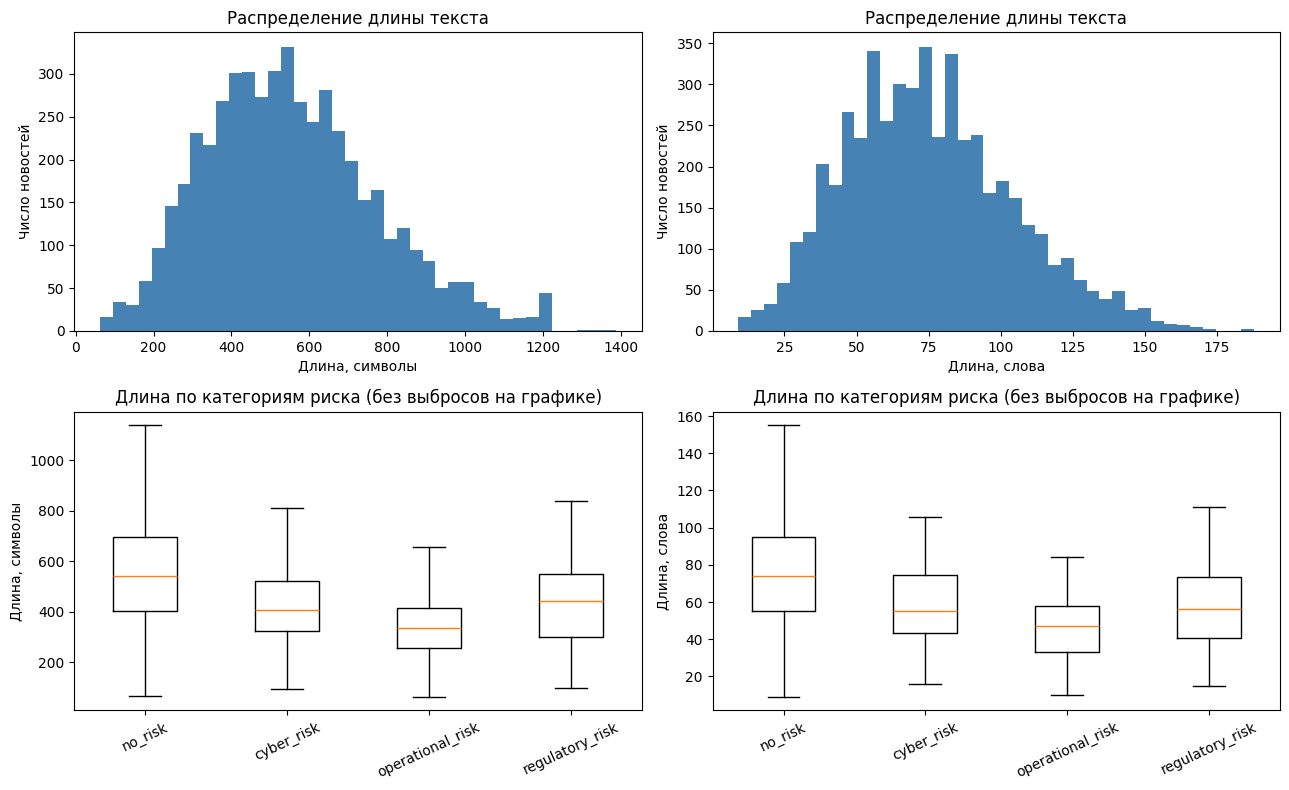

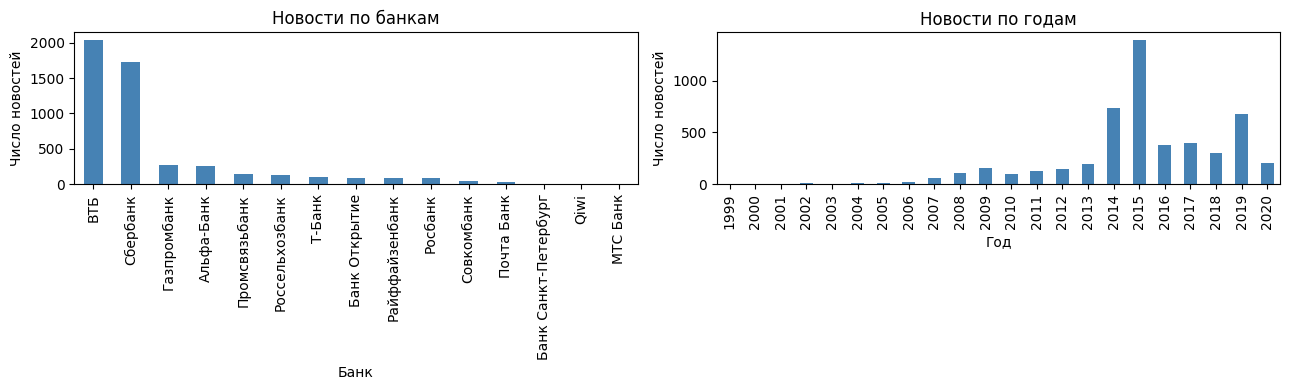

In [4]:
split_order = ['train', 'valid', 'test']
overview = df.groupby('split').agg(news=('sample_id', 'size'), groups=('event_group_id', 'nunique'))
overview = overview.reindex(split_order)
counts = pd.crosstab(df['split'], df['risk_type_4cls']).reindex(index=split_order, columns=LABELS, fill_value=0)
display(overview, counts, counts.div(counts.sum(axis=1), axis=0).round(4))
save_csv('eda/split_overview.csv', overview.reset_index())
save_csv('eda/class_counts.csv', counts.reset_index())
class_groups = df.groupby(['split', 'risk_type_4cls'])['event_group_id'].nunique().unstack(fill_value=0)
save_csv('eda/class_group_counts.csv', class_groups.reset_index())
display(pd.Series({'Всего новостей': len(df), 'Банков': df['entity_norm'].nunique(),
                   'Групп событий': df['event_group_id'].nunique(),
                   'Первый год': df['published_year'].min(), 'Последний год': df['published_year'].max()}))
bank_counts = df['entity_norm'].value_counts().rename_axis('bank').reset_index(name='news')
year_counts = df['published_year'].value_counts().sort_index().rename_axis('year').reset_index(name='news')
source_counts = df['source'].value_counts().rename_axis('source').reset_index(name='news')
for name, table in [('banks', bank_counts), ('years', year_counts), ('sources', source_counts)]:
    save_csv(f'eda/{name}.csv', table)
bank_risk = pd.crosstab(df['entity_norm'], df['risk_type_4cls']).reindex(columns=LABELS, fill_value=0)
year_risk = pd.crosstab(df['published_year'], df['risk_type_4cls']).reindex(columns=LABELS, fill_value=0)
save_csv('eda/bank_risk_counts.csv', bank_risk.reset_index())
save_csv('eda/year_risk_counts.csv', year_risk.reset_index())
display(source_counts, bank_risk, year_risk)
print(f"Доля крупнейшего банка: {bank_counts['news'].max()/len(df):.1%}; "
      f"доля наиболее представленного года: {year_counts['news'].max()/len(df):.1%}.")
lengths = df[['sample_id', 'split', 'risk_type_4cls']].copy()
lengths['characters'] = df['text_fragment'].str.len()
lengths['words'] = df['text_fragment'].str.split().str.len()
summary = lengths.groupby('risk_type_4cls')[['characters', 'words']].describe(percentiles=[.1, .25, .5, .75, .9, .95])
display(summary)
save_csv('eda/text_lengths.csv', lengths)
save_csv('eda/length_summary.csv', summary.reset_index())
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for j, (col, label) in enumerate([('characters', 'Длина, символы'), ('words', 'Длина, слова')]):
    axes[0, j].hist(lengths[col], bins=40, color='steelblue')
    axes[0, j].set(xlabel=label, ylabel='Число новостей', title='Распределение длины текста')
    label_key='tick_labels' if 'tick_labels' in inspect.signature(axes[1,j].boxplot).parameters else 'labels'
    axes[1,j].boxplot([lengths.loc[lengths['risk_type_4cls'].eq(c),col] for c in LABELS],
        **{label_key:LABELS},showfliers=False)
    axes[1, j].set(ylabel=label, title='Длина по категориям риска (без выбросов на графике)')
    axes[1, j].tick_params(axis='x', rotation=25)
plt.tight_layout(); save_fig('eda/text_lengths')
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
bank_counts.set_index('bank')['news'].plot.bar(ax=axes[0], color='steelblue')
axes[0].set(title='Новости по банкам', xlabel='Банк', ylabel='Число новостей')
year_counts.set_index('year')['news'].plot.bar(ax=axes[1], color='steelblue')
axes[1].set(title='Новости по годам', xlabel='Год', ylabel='Число новостей')
plt.tight_layout(); save_fig('eda/banks_years')


In [5]:

raw_repeats = df.loc[df['text_fragment'].duplicated(keep=False),
    ['sample_id', 'event_group_id', 'split', 'risk_type_4cls']].copy()
raw_repeats['text_sha256'] = df.loc[raw_repeats.index, 'text_fragment'].map(
    lambda text: hashlib.sha256(text.encode('utf-8')).hexdigest())
save_csv('eda/raw_exact_text_repeats.csv', raw_repeats)
print('Строк в побайтово одинаковых текстах:', len(raw_repeats))
normalized = df['text_fragment'].str.casefold().str.replace(r'\s+', ' ', regex=True).str.strip()
duplicate_rows = df.loc[normalized.duplicated(keep=False), ['sample_id', 'event_group_id', 'split', 'risk_type_4cls']].copy()
duplicate_rows['text_key'] = normalized.loc[duplicate_rows.index]
duplicate_rows['across_splits'] = duplicate_rows.groupby('text_key')['split'].transform('nunique').gt(1)
save_csv('eda/exact_text_repeats.csv', duplicate_rows)
print('Строк в точных нормализованных повторах:', len(duplicate_rows),
      '; из них в межвыборочных повторах:', int(duplicate_rows['across_splits'].sum()))
group_overlap = []
for a, b in [('train', 'valid'), ('train', 'test'), ('valid', 'test')]:
    overlap = set(df.loc[df['split'].eq(a), 'event_group_id']) & set(df.loc[df['split'].eq(b), 'event_group_id'])
    group_overlap.append({'split_a': a, 'split_b': b, 'shared_event_groups': len(overlap)})
save_csv('eda/group_overlap.csv', pd.DataFrame(group_overlap))
from sklearn.neighbors import NearestNeighbors
train_texts = parts['train']['text_fragment']
audit_vectorizer = TfidfVectorizer(analyzer='char', ngram_range=(3, 5), min_df=2,
                                  max_features=30000, sublinear_tf=True, dtype=np.float32)
train_vectors = audit_vectorizer.fit_transform(train_texts)
all_vectors = audit_vectorizer.transform(df['text_fragment'])
neighbors = NearestNeighbors(n_neighbors=2, metric='cosine', algorithm='brute', n_jobs=1).fit(train_vectors)
train_ids = parts['train']['sample_id'].to_numpy()
pair_rows, seen_pairs = [], set()
for start in range(0, len(df), 256):
    distances, indices = neighbors.kneighbors(all_vectors[start:start+256])
    for local_i, (ds, js) in enumerate(zip(distances, indices)):
        row = df.iloc[start+local_i]
        for distance, j in zip(ds, js):
            if row['sample_id'] == train_ids[j]:
                continue
            similarity = 1-float(distance)
            key = tuple(sorted([str(row['sample_id']), str(train_ids[j])]))
            if similarity >= .95 and key not in seen_pairs:
                pair_rows.append({'sample_id': row['sample_id'], 'train_sample_id': train_ids[j],
                                  'split': row['split'], 'train_split': 'train', 'similarity': similarity})
                seen_pairs.add(key)
            break
near_pairs = pd.DataFrame(pair_rows, columns=['sample_id', 'train_sample_id', 'split', 'train_split', 'similarity'])
save_csv('eda/near_duplicate_candidates.csv', near_pairs)
print('Кандидатов на близкие повторы (сравнение с train):', len(near_pairs),
      '. Лексическое сходство не доказывает тождество события; строки не удаляются.')
terms_vectorizer = CountVectorizer(ngram_range=(1, 2), min_df=3, max_df=.98, max_features=30000)
terms_x = terms_vectorizer.fit_transform(train_texts)
terms = terms_vectorizer.get_feature_names_out()
term_totals = np.asarray(terms_x.sum(axis=0)).ravel()
frequent = pd.DataFrame({'ngram': terms, 'count': term_totals})
frequent['order'] = np.where(frequent.ngram.str.contains(' '), 2, 1)
frequent = frequent.sort_values('count', ascending=False).groupby('order', group_keys=False).head(15)
save_csv('eda/train_frequent_ngrams.csv', frequent); display(frequent)
distinctive = []
for target in ['alert_flag', 'risk_type_4cls']:
    for label in sorted(parts['train'][target].unique(), key=str):
        mask = parts['train'][target].eq(label).to_numpy()
        inside = np.asarray(terms_x[mask].sum(axis=0)).ravel()+1
        outside = np.asarray(terms_x[~mask].sum(axis=0)).ravel()+1
        log_ratio = np.log(inside/inside.sum())-np.log(outside/outside.sum())
        for j in np.argsort(-log_ratio)[:15]:
            distinctive.append({'target': target, 'class': str(label), 'ngram': terms[j],
                                'smoothed_log_ratio': float(log_ratio[j]), 'class_count': int(inside[j]-1)})
distinctive = pd.DataFrame(distinctive)
save_csv('eda/train_characteristic_ngrams.csv', distinctive); display(distinctive)
del train_vectors, all_vectors, terms_x


Строк в побайтово одинаковых текстах: 104
Строк в точных нормализованных повторах: 104 ; из них в межвыборочных повторах: 0
Кандидатов на близкие повторы (сравнение с train): 61 . Лексическое сходство не доказывает тождество события; строки не удаляются.


,ngram,count,order
9456,на,5999,1
12645,по,3544,1
3387,втб,2596,1
20524,что,2230,1
16479,сбербанк,1986,1
1767,банк,1768,1
10279,не,1751,1
1875,банка,1352,1
4144,года,1339,1
5820,за,1331,1


,target,class,ngram,smoothed_log_ratio,class_count
0,alert_flag,0,ставки,3.932042,480
1,alert_flag,0,капитал,3.737589,395
2,alert_flag,0,ставки по,3.369303,273
3,alert_flag,0,млрд руб,3.305251,256
4,alert_flag,0,андрей,3.224235,236
...,...,...,...,...,...
85,risk_type_4cls,regulatory_risk,роснефть санкционный,4.195177,4
86,risk_type_4cls,regulatory_risk,по паспортам,4.195177,4
87,risk_type_4cls,regulatory_risk,украине распространил,3.972034,3
88,risk_type_4cls,regulatory_risk,бумагами сбербанка,3.972034,3


## 4. Проверка форматов входа

Сначала проверяется, добавляет ли заголовок информацию к `text_fragment`. Совпадение входов делает их сравнение бессодержательным.

Для `text_without_title` удаляется только точный префикс `title`, отделённый пробелами. Если заголовок пуст, не выделяется однозначно или встречается в оставшемся теле, текст сохраняется и получает соответствующий статус. Произвольное первое предложение не удаляется.

Это частичная обработка: все исходные строки остаются в обучении. Строгая оценка трёх входов проводится дополнительно на общем подмножестве, где заголовок удалён надёжно. Правило не использует метки; ниже показаны покрытие и примеры.


In [6]:
import pandas as pd


def remove_title_strict(title, text):
    """Удаляет только точный префикс из title и разделяющие пробелы."""
    text = '' if text is None or pd.isna(text) else str(text)
    title = '' if title is None or pd.isna(title) else str(title)
    result = dict(body=text, candidate_body=text, status='unresolved', changed=False, removed_chars=0,
                  prefix_matched=False, matched_prefix_chars=0, prefix_title_removed=False, title_still_in_body=False,
                  body_starts_with_title=False, paired_title_eligible=False)
    if not title.strip():
        result['status'] = 'missing_title'
        return result
    if title != title.strip():
        result['status'] = 'ambiguous_title_whitespace'
        return result
    if not text.startswith(title):
        result['status'] = 'title_not_exact_prefix'
        return result
    cut = len(title)
    if cut == len(text):
        result['status'] = 'empty_body'
        return result
    if not text[cut].isspace():
        result['status'] = 'no_prefix_boundary'
        return result
    while cut < len(text) and text[cut].isspace():
        cut += 1
    if cut == len(text):
        result['status'] = 'empty_body'
        return result
    body = text[cut:]
    residual = title.casefold() in body.casefold()
    repeated_prefix = body.casefold().startswith(title.casefold())
    if residual:
        result.update(candidate_body=body, status='ambiguous_residual_title',
                      prefix_matched=True, matched_prefix_chars=cut,
                      title_still_in_body=True, body_starts_with_title=repeated_prefix)
        return result
    result.update(body=body, status='removed_prefix',
                  changed=body != text, removed_chars=cut, prefix_title_removed=True,
                  prefix_matched=True, matched_prefix_chars=cut, candidate_body=body,
                  title_still_in_body=residual, body_starts_with_title=repeated_prefix,
                  paired_title_eligible=not residual)
    assert body == text[cut:]
    assert not result['paired_title_eligible'] or title.casefold() not in body.casefold()
    return result


def audit_data(frame):
    """Проверяет все строки; метки и исходные тексты не изменяются."""
    audit = frame[['sample_id', 'event_group_id', 'split', 'alert_flag', 'risk_type_4cls']].copy()
    records = pd.DataFrame([remove_title_strict(title, text)
                           for title, text in zip(frame['title'], frame['text_fragment'])],
                          index=frame.index)
    for column in records:
        audit[column] = records[column]
    return audit


title_audit=audit_data(df).set_index('sample_id',drop=False)
df['text_without_title']=title_audit.loc[df.sample_id,'body'].to_numpy()
df['title_eligible']=title_audit.loc[df.sample_id,'paired_title_eligible'].to_numpy(dtype=bool)
assert df.loc[df.title_eligible,'text_without_title'].ne(df.loc[df.title_eligible,'text_fragment']).all()
assert df.loc[~df.title_eligible,'text_without_title'].eq(df.loc[~df.title_eligible,'text_fragment']).all()
parts={s:df[df.split.eq(s)].reset_index(drop=True) for s in ['train','valid','test']}
save_csv('data_audit/title_removal.csv',title_audit.reset_index(drop=True))
counts=title_audit.groupby(['split','status']).size().rename('rows').reset_index()
save_csv('data_audit/title_status_counts.csv',counts);display(counts)
print('Изменено текстов:',int(df.title_eligible.sum()),'из',len(df))
print('Неоднозначных или отсутствующих заголовков:',int((~df.title_eligible).sum()))
def title_and_text(title,text):
    title,text=title.strip(),text.strip()
    return text if not title or title.casefold() in text[:max(300,len(title)+40)].casefold() else title+'. '+text
combined=pd.Series([title_and_text(t,x) for t,x in zip(df.title,df.text_fragment)],index=df.index)
print('Диагностика text_title: совпадает с text:',int(combined.eq(df.text_fragment).sum()))
print('text_title и text совпадают после удаления внешних пробелов:',int(combined.eq(df.text_fragment.str.strip()).sum()))
examples=df[['sample_id','title','text_fragment','text_without_title','title_eligible']].copy()
examples['status']=title_audit.loc[examples.sample_id,'status'].to_numpy()
for col in ['text_fragment','text_without_title']:examples[col]=examples[col].str.slice(0,240)
display(pd.concat([examples[examples.title_eligible].head(3),examples[~examples.title_eligible].head(3)]))
TITLE_AUDIT_SHA=hashlib.sha256(title_audit[['sample_id','body','status','paired_title_eligible']].to_csv(index=False,lineterminator='\n').encode()).hexdigest()
save_json('data_audit/title_policy.json',dict(policy=TITLE_POLICY,audit_sha256=TITLE_AUDIT_SHA,
    changed=int(df.title_eligible.sum()),unchanged=int((~df.title_eligible).sum())))


,split,status,rows
0,test,ambiguous_residual_title,17
1,test,removed_prefix,734
2,train,ambiguous_residual_title,83
3,train,missing_title,1
4,train,removed_prefix,3451
5,valid,ambiguous_residual_title,14
6,valid,removed_prefix,741


Изменено текстов: 4926 из 5041
Неоднозначных или отсутствующих заголовков: 115
Диагностика text_title: совпадает с text: 5036
text_title и text совпадают после удаления внешних пробелов: 5041


,sample_id,title,text_fragment,text_without_title,title_eligible,status
0,ml_nat5_final_000001,Газпромбанк и РСХБ самоустранились от проекта ...,Газпромбанк и РСХБ самоустранились от проекта ...,"РСХБ и ГПБ заявили, что проект не соответствуе...",True,removed_prefix
1,ml_nat5_final_000002,Хакеры четыре года грабили клиентов Сбербанка ...,Хакеры четыре года грабили клиентов Сбербанка ...,Во время задержания хакеры попытались смыть в ...,True,removed_prefix
2,ml_nat5_final_000003,"Exxon и ""Роснефть"" прекратили бурение в Арктик...","Exxon и ""Роснефть"" прекратили бурение в Арктик...",Вместе с тем страны ЕС расширили и индивидуаль...,True,removed_prefix
13,ml_nat5_final_000014,Банкоматы Сбербанка возобновили прием тысячеру...,Банкоматы Сбербанка возобновили прием тысячеру...,Банкоматы Сбербанка возобновили прием тысячеру...,False,ambiguous_residual_title
31,ml_nat5_final_000032,"""Альфа-банк"" реструктуризировал долги ""ЮТэйр""","""Альфа-банк"" реструктуризировал долги ""ЮТэйр"" ...","""Альфа-банк"" реструктуризировал долги ""ЮТэйр"" ...",False,ambiguous_residual_title
153,ml_nat5_final_000154,Прибыль ВТБ по МСФО сократилась в I квартале н...,Прибыль ВТБ по МСФО сократилась в I квартале н...,Прибыль ВТБ по МСФО сократилась в I квартале н...,False,ambiguous_residual_title


## 5. Подготовка и протокол оценки

Train делится по `event_group_id`: связанные новости остаются вместе. Во всех частях представлены все классы.

| Часть | Строк | Назначение |
|---|---:|---|
| fit | 2 119 | Обучение |
| stop | 708 | Выбор checkpoint и конфигурации |
| calibration | 708 | Бинарный порог |

Гиперпараметры классических моделей выбираются групповой CV из трёх фолдов внутри fit: по AP для бинарной задачи и Macro F1 для многоклассовой. Итоговые модели обучаются на fit.

Checkpoint mDeBERTa выбирается по AP на stop без подбора порога по эпохам; для четырёх классов — по Macro F1. Затем бинарный порог один раз максимизирует F1 на полной calibration. Порог сохраняется для всех внешних оценок, включая строгое подмножество абляции. Valid и test не участвуют в настройке.


In [7]:
train = parts['train']
folds = np.full(len(train), -1, dtype=int)
outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
for fold, (_, ix) in enumerate(outer.split(train, train.risk_type_4cls, train.event_group_id)):
    folds[ix] = fold
role_folds = ROLE_FOLDS
roles = {name: train[np.isin(folds, selected)].reset_index(drop=True)
         for name, selected in role_folds.items()}
assert (folds >= 0).all()
for a, b in [('fit', 'stop'), ('fit', 'calibration'), ('stop', 'calibration')]:
    assert not set(roles[a].event_group_id) & set(roles[b].event_group_id)
for name, frame in roles.items():
    counts = frame.risk_type_4cls.value_counts().reindex(LABELS, fill_value=0)
    assert counts.min() >= (15 if name == 'fit' else 5), (name, counts.to_dict())
    group_counts = frame.groupby('risk_type_4cls').event_group_id.nunique().reindex(LABELS, fill_value=0)
    assert group_counts.min() >= (10 if name == 'fit' else 5), (name, group_counts.to_dict())
cv_splits = list(StratifiedGroupKFold(3, shuffle=True, random_state=SEED).split(
    roles['fit'], roles['fit'].risk_type_4cls, roles['fit'].event_group_id))
for tr, va in cv_splits:
    for ix in [tr, va]: assert set(roles['fit'].iloc[ix].risk_type_4cls) == set(LABELS)
    assert not set(roles['fit'].iloc[tr].event_group_id) & set(roles['fit'].iloc[va].event_group_id)
membership = pd.concat([f[['sample_id', 'event_group_id']].assign(role=n) for n, f in roles.items()])
save_csv('protocol/train_membership.csv', membership)
SPLIT_SHA = hashlib.sha256(membership.to_csv(index=False).encode()).hexdigest()
protocol = dict(version=PROTOCOL_VERSION, dataset_sha256=DATA_SHA, split_sha256=SPLIT_SHA,
    role_folds=role_folds, title_audit_sha256=TITLE_AUDIT_SHA, title_policy=TITLE_POLICY, binary_inputs=BINARY_INPUTS, split_choice='train class/group support only; no model metrics',
    profile=PROFILE, seeds=SEEDS, main_seed=42, binary_selection='stop_AP',
    multiclass_selection='stop_macro_F1', dl=DL_CONFIG, bootstrap_replicates=BOOTSTRAP_REPS,
    precision_targets=PRECISION_TARGETS, min_alerts=MIN_ALERTS,
    hardware=dict(gpu=torch.cuda.get_device_name(0), devices=torch.cuda.device_count(), cuda=torch.version.cuda,
        bf16=torch.cuda.is_bf16_supported(), fp16=not torch.cuda.is_bf16_supported()),
    historical_test=True, new_independent_test=False)
save_json('protocol/plan.json', protocol)
role_counts = pd.crosstab(membership.role, train.set_index('sample_id').loc[membership.sample_id, 'risk_type_4cls'].to_numpy()).reindex(columns=LABELS)
display(role_counts)
save_csv('protocol/class_counts.csv', role_counts.reset_index())


col_0,no_risk,cyber_risk,operational_risk,regulatory_risk
role,,,,
calibration,673,11,16,8
fit,2011,49,39,20
stop,675,14,12,7


### Техническая проверка

Маленькая синтетическая модель проверяет полный цикл Trainer: обучение, метрики, checkpoint, загрузку лучших весов, predict и запись результатов. Общие настройки совпадают с основным экспериментом; технические показатели не входят в научные таблицы.


In [8]:
def logits_array(prediction):
    x = prediction.predictions
    return np.asarray(x[0] if isinstance(x, tuple) else x)

def positive_probability(logits):
    x = np.asarray(logits, dtype=np.float64); x = x-x.max(axis=1, keepdims=True)
    exp = np.exp(x)
    return exp[:,1] / exp.sum(axis=1)

def checkpoint_binary(prediction):
    # Checkpoint выбирается по AP без настройки порога.
    return {'ap':float(average_precision_score(prediction.label_ids, positive_probability(logits_array(prediction))))}

def checkpoint_multi(prediction):
    return {'macro_f1':float(f1_score(prediction.label_ids, logits_array(prediction).argmax(axis=1),
        labels=range(4), average='macro', zero_division=0))}

def make_training_args(folder, task, seed, **overrides):
    params = dict(output_dir=str(folder), num_train_epochs=DL_CONFIG['epochs'],
        learning_rate=DL_CONFIG['learning_rate'], weight_decay=DL_CONFIG['weight_decay'],
        warmup_ratio=DL_CONFIG['warmup_ratio'], per_device_train_batch_size=DL_CONFIG['train_batch'],
        per_device_eval_batch_size=DL_CONFIG['eval_batch'], gradient_accumulation_steps=DL_CONFIG['accumulation'],
        eval_accumulation_steps=1, lr_scheduler_type='linear', optim='adamw_torch', max_grad_norm=1.0,
        eval_strategy='epoch', save_strategy='epoch', logging_strategy='epoch',
        load_best_model_at_end=True, metric_for_best_model='ap' if task=='binary' else 'macro_f1',
        greater_is_better=True, save_total_limit=1, save_only_model=True, save_safetensors=True,
        fp16=not torch.cuda.is_bf16_supported(), bf16=torch.cuda.is_bf16_supported(),
        gradient_checkpointing=True, gradient_checkpointing_kwargs={'use_reentrant':False},
        seed=seed, data_seed=seed, report_to='none', dataloader_num_workers=0,
        dataloader_pin_memory=True, remove_unused_columns=True)
    params.update(overrides)
    return TrainingArguments(**params)


args_probe=make_training_args(OUTPUT/'technical_smoke/arguments_probe','binary',42)
assert args_probe.world_size==1 and args_probe.n_gpu==TRAIN_DEVICE_COUNT
assert args_probe.train_batch_size*args_probe.gradient_accumulation_steps==DL_CONFIG['global_batch_size']
save_json('runtime_training_settings.json',dict(devices=TRAIN_DEVICE_COUNT,
    per_device_batch=DL_CONFIG['train_batch'],accumulation=DL_CONFIG['accumulation'],
    global_batch=DL_CONFIG['global_batch_size'],fp16=args_probe.fp16,bf16=args_probe.bf16))
del args_probe


In [9]:
def run_trainer_smoke_test(use_cpu=False):
    "Полный цикл Trainer на синтетических данных."
    from tokenizers import Tokenizer
    from tokenizers.models import WordLevel
    from tokenizers.pre_tokenizers import Whitespace
    from transformers import PreTrainedTokenizerFast

    folder = OUTPUT / 'technical_smoke'
    folder.mkdir(parents=True, exist_ok=True)
    ephemeral = folder / 'temporary_models'
    if ephemeral.exists():
        assert ephemeral.resolve().parent == folder.resolve()
        shutil.rmtree(ephemeral)
    ephemeral.mkdir()
    vocab = {token: i for i, token in enumerate(['[PAD]', '[UNK]', 'bank', 'news', 'risk',
        'ordinary', 'context', 'report', 'event', 'title', 'short', 'long'])}
    backend = Tokenizer(WordLevel(vocab=vocab, unk_token='[UNK]'))
    backend.pre_tokenizer = Whitespace()
    local_tokenizer = PreTrainedTokenizerFast(tokenizer_object=backend,
        pad_token='[PAD]', unk_token='[UNK]', model_max_length=64,
        model_input_names=['input_ids', 'attention_mask'])
    local_collator = DataCollatorWithPadding(local_tokenizer, pad_to_multiple_of=8)

    class SyntheticNews(torch.utils.data.Dataset):
        def __init__(self, count, classes, labelled=True):
            self.labels = [i % classes for i in range(count)]
            texts = [('bank news risk ' if label else 'bank news ordinary ') +
                     'context report ' * (1 + i % 3) for i, label in enumerate(self.labels)]
            self.encoded = local_tokenizer(texts, truncation=True, max_length=32)
            self.labelled = labelled
        def __len__(self): return len(self.labels)
        def __getitem__(self, index):
            item = {key: value[index] for key, value in self.encoded.items()}
            if self.labelled: item['labels'] = self.labels[index]
            return item

    reports = []
    started = time.perf_counter()
    save_json('technical_smoke/report.json', dict(status='running', technical_only=True,
        research_result=False, use_cpu=use_cpu))
    try:
        for task, classes, metric in [('binary', 2, 'ap'), ('multiclass', 4, 'macro_f1')]:
            set_seed(42)
            model = DebertaV2ForSequenceClassification(DebertaV2Config(
                vocab_size=len(vocab), hidden_size=32, num_hidden_layers=1,
                num_attention_heads=4, intermediate_size=64, max_position_embeddings=64,
                pad_token_id=vocab['[PAD]'], num_labels=classes))
            train_data = SyntheticNews(16, classes)
            eval_data = SyntheticNews(8, classes)
            predict_data = SyntheticNews(8, classes, labelled=False)
            overrides = dict(num_train_epochs=2, disable_tqdm=True)
            if use_cpu:
                overrides.update(use_cpu=True, fp16=False, bf16=False, dataloader_pin_memory=False)
            args = make_training_args(ephemeral / task / 'checkpoints', task, 42, **overrides)
            metric_function = checkpoint_binary if task == 'binary' else checkpoint_multi
            trainer = Trainer(model=model, args=args, train_dataset=train_data,
                eval_dataset=eval_data, data_collator=local_collator,
                processing_class=local_tokenizer, compute_metrics=metric_function,
                callbacks=[EarlyStoppingCallback(early_stopping_patience=DL_CONFIG['patience'])])
            trainer.train()
            assert trainer.state.global_step >= 2, 'Smoke: не выполнены две эпохи обучения'
            best = Path(trainer.state.best_model_checkpoint)
            assert best.is_dir() and (best / 'model.safetensors').is_file()
            checkpoint_state = json.loads((best / 'trainer_state.json').read_text(encoding='utf-8'))
            assert checkpoint_state['best_model_checkpoint'] == str(best)
            assert np.isfinite(trainer.state.best_metric)
            assert any('eval_' + metric in row for row in trainer.state.log_history)
            restored = DebertaV2ForSequenceClassification.from_pretrained(best)
            current = trainer.accelerator.unwrap_model(trainer.model)
            for key, value in current.state_dict().items():
                assert torch.equal(value.detach().cpu(), restored.state_dict()[key].cpu()), key
            evaluated = trainer.predict(eval_data)
            assert np.isfinite(evaluated.metrics['test_' + metric])
            predicted = logits_array(trainer.predict(predict_data))
            assert predicted.shape == (8, classes) and np.isfinite(predicted).all()
            saved_model = ephemeral / task / 'saved_model'
            trainer.save_model(str(saved_model))
            local_tokenizer.save_pretrained(saved_model)
            assert (saved_model / 'model.safetensors').is_file()
            frame = pd.DataFrame({'synthetic_id': [f'smoke_{i:03d}' for i in range(8)],
                'label': eval_data.labels, 'prediction': predicted.argmax(axis=1)})
            for i in range(classes): frame[f'logit_{i}'] = predicted[:, i]
            relative = f'technical_smoke/{task}_predictions.csv'
            save_csv(relative, frame)
            assert len(pd.read_csv(OUTPUT / relative)) == 8
            reports.append(dict(task=task, technical_only=True, synthetic_rows=16,
                training_steps=trainer.state.global_step, best_metric=trainer.state.best_metric,
                prediction_rows=len(frame), best_weights_reloaded=True,
                metric_computed=True, checkpoint_saved=True, predictions_saved=True,
                trainer_settings={key: args.to_dict()[key] for key in [
                    'eval_strategy', 'save_strategy', 'logging_strategy', 'load_best_model_at_end',
                    'metric_for_best_model', 'save_only_model', 'save_safetensors',
                    'gradient_accumulation_steps', 'gradient_checkpointing',
                    'gradient_checkpointing_kwargs', 'fp16', 'bf16', 'optim']}))
            del trainer, current, restored, model, evaluated, predicted
            gc.collect()
            if torch.cuda.is_available(): torch.cuda.empty_cache()
        result = dict(status='passed', technical_only=True, research_result=False,
            use_cpu=use_cpu, seconds=time.perf_counter() - started, tasks=reports)
        save_json('technical_smoke/report.json', result)
        assert ephemeral.resolve().parent == folder.resolve()
        shutil.rmtree(ephemeral)
        print('Smoke test Trainer: обучение, метрики, checkpoint, лучшая модель и predict — OK.')
        return result
    except Exception as error:
        save_json('technical_smoke/report.json', dict(status='failed', technical_only=True,
            research_result=False, use_cpu=use_cpu, error_type=type(error).__name__, error=str(error)))
        raise
    finally:
        set_seed(42)
        gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()

smoke_report = run_trainer_smoke_test()


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


{'loss': 0.6929, 'grad_norm': 0.06990070641040802, 'learning_rate': 0.0, 'epoch': 1.0}
{'eval_loss': 0.6931481957435608, 'eval_ap': 0.5083333333333333, 'eval_runtime': 0.017, 'eval_samples_per_second': 469.943, 'eval_steps_per_second': 58.743, 'epoch': 1.0}
{'loss': 0.6937, 'grad_norm': 0.05382658541202545, 'learning_rate': 2e-05, 'epoch': 2.0}
{'eval_loss': 0.6931480765342712, 'eval_ap': 0.525, 'eval_runtime': 0.0123, 'eval_samples_per_second': 652.036, 'eval_steps_per_second': 81.505, 'epoch': 2.0}
{'train_runtime': 2.188, 'train_samples_per_second': 14.626, 'train_steps_per_second': 0.914, 'train_loss': 0.69329434633255, 'epoch': 2.0}


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/transformers/trainer.py:4380: UserWarning: mtime may not be reliable on this filesystem, falling back to numerical ordering
  warnings.warn("mtime may not be reliable on this filesystem, falling back to numerical ordering")
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.


{'loss': 1.3872, 'grad_norm': 0.05663318186998367, 'learning_rate': 0.0, 'epoch': 1.0}
{'eval_loss': 1.386303424835205, 'eval_macro_f1': 0.1, 'eval_runtime': 0.0133, 'eval_samples_per_second': 600.914, 'eval_steps_per_second': 75.114, 'epoch': 1.0}
{'loss': 1.3878, 'grad_norm': 0.05268842726945877, 'learning_rate': 2e-05, 'epoch': 2.0}
{'eval_loss': 1.3863033056259155, 'eval_macro_f1': 0.1, 'eval_runtime': 0.014, 'eval_samples_per_second': 572.455, 'eval_steps_per_second': 71.557, 'epoch': 2.0}
{'train_runtime': 0.1682, 'train_samples_per_second': 190.243, 'train_steps_per_second': 11.89, 'train_loss': 1.3874797821044922, 'epoch': 2.0}
Smoke test Trainer: обучение, метрики, checkpoint, лучшая модель и predict — OK.


In [10]:
from pathlib import Path
import json, warnings


def resources_before_run(name):
    "Проверка ресурсов для основных обучений."
    planned = {item['name']: item for item in DL_RUN_PLAN}
    assert name in planned, f'Неизвестный запуск: {name}'
    completed, timings, weight_sizes = [], [], []
    for item in DL_RUN_PLAN:
        folder = OUTPUT / 'runs' / item['name']
        marker, record_path = folder / 'complete.json', folder / 'record.json'
        if not marker.exists():
            continue
        assert record_path.is_file(), f'Отсутствует record.json завершённого запуска: {folder}'
        record = json.loads(record_path.read_text(encoding='utf-8'))
        assert record['name'] == item['name'], f'Неверный record.json: {folder}'
        completed.append(item['name'])
        epochs = float(record.get('epochs_completed') or 0)
        elapsed = float(record.get('seconds') or 0)
        training = float(record.get('train_seconds') or elapsed)
        if epochs > 0 and training > 0:
            timings.append((training / epochs, max(0., elapsed - training)))
        size = int(record.get('model_weight_bytes') or 0)
        if size > 0:
            weight_sizes.append(size)
    remaining = [item for item in DL_RUN_PLAN if item['name'] not in completed]
    bytes_per_model = max(weight_sizes, default=280_000_000 * 4)
    retained_remaining = sum(int(item['seed'] == 42) for item in remaining)
    checkpoint_reserve = 2 * bytes_per_model if remaining else 0
    headroom = 2**30
    future_increment = retained_remaining * bytes_per_model + checkpoint_reserve + headroom
    scope = Path('/kaggle/working') if OUTPUT.is_relative_to(Path('/kaggle/working')) else OUTPUT
    current_bytes = sum(p.stat().st_size for p in scope.rglob('*') if p.is_file() and not p.is_symlink())
    free_bytes = shutil.disk_usage(OUTPUT).free
    projected_bytes = current_bytes + future_increment
    output_limit = int(MAX_OUTPUT_GB * 10**9)
    devices = max(1, int(torch.cuda.device_count()))
    microbatches = int(np.ceil(len(roles['fit']) / (DL_CONFIG['train_batch'] * devices)))
    steps_per_epoch = int(np.ceil(microbatches / DL_CONFIG['accumulation']))
    elapsed_hours = (time.monotonic() - SESSION_STARTED_MONOTONIC) / 3600
    available_hours = max(0., SESSION_BUDGET_HOURS - elapsed_hours)
    estimated_remaining_hours = None
    if timings and remaining:
        # Прогноз по измеренному времени с запасом.
        per_epoch = float(np.quantile([t[0] for t in timings], .75))
        overhead = max(t[1] for t in timings)
        estimated_remaining_hours = len(remaining) * (1.2 * per_epoch * DL_CONFIG['epochs'] + overhead) / 3600
    elif not remaining:
        estimated_remaining_hours = 0.
    report = dict(current_run=name, planned_runs=len(DL_RUN_PLAN), completed_runs=completed,
        remaining_runs=[item['name'] for item in remaining], bytes_per_model_estimate=bytes_per_model,
        remaining_retained_models=retained_remaining, temporary_checkpoint_reserve_bytes=checkpoint_reserve,
        headroom_bytes=headroom, output_scope=str(scope), current_output_bytes=current_bytes,
        projected_peak_bytes_conservative=projected_bytes, output_limit_bytes=output_limit,
        filesystem_free_bytes=free_bytes, additional_disk_reserve_bytes=future_increment,
        optimizer_steps_per_epoch_estimate=steps_per_epoch,
        remaining_optimizer_steps_upper_estimate=len(remaining) * steps_per_epoch * DL_CONFIG['epochs'],
        session_elapsed_hours=elapsed_hours, configured_session_budget_hours=SESSION_BUDGET_HOURS,
        available_session_hours=available_hours, estimated_remaining_hours=estimated_remaining_hours,
        timing_basis_real_completed_runs=len(timings), tiny_smoke_excluded=True,
        duration_is_guaranteed=False)
    save_json('resource_preflight.json', report)
    plan_rows = [dict(**item, completed=item['name'] in completed,
        optimizer_steps_per_epoch_estimate=steps_per_epoch,
        max_epochs=DL_CONFIG['epochs']) for item in DL_RUN_PLAN]
    save_csv('resource_plan.csv', pd.DataFrame(plan_rows))
    assert projected_bytes <= output_limit, (
        f'Недостаточно бюджета Output: оценка {projected_bytes/10**9:.2f} GB '
        f'при лимите {MAX_OUTPUT_GB:.1f} GB. Конфигурация не изменена.')
    assert free_bytes >= future_increment, (
        f'Недостаточно свободного диска: {free_bytes/10**9:.2f} GB; '
        f'нужен резерв {future_increment/10**9:.2f} GB. Конфигурация не изменена.')
    try:
        gpu_bytes = torch.cuda.get_device_properties(0).total_memory
    except (AttributeError, RuntimeError, AssertionError):
        gpu_bytes = None
    if gpu_bytes is not None and gpu_bytes < 12 * 2**30:
        warnings.warn('GPU имеет меньше 12 GiB памяти: реальная mDeBERTa может не поместиться; параметры не изменены.')
    if estimated_remaining_hours is not None and estimated_remaining_hours > available_hours:
        warnings.warn(f'Оценка оставшегося времени {estimated_remaining_hours:.1f} ч превышает '
            f'остаток настроенного бюджета {available_hours:.1f} ч. '
            'Для продолжения необходимо сохранить весь Output; профиль не изменён.')
    if not timings and remaining:
        warnings.warn('Длительность FULL пока не измерена: синтетический smoke test не оценивает скорость mDeBERTa.')
    return report


def report_resource_progress():
    pending = [item for item in DL_RUN_PLAN
        if not (OUTPUT/'runs'/item['name']/'complete.json').is_file()]
    return resources_before_run((pending[0] if pending else DL_RUN_PLAN[-1])['name'])

report_resource_progress()


/tmp/ipykernel_50/3426518933.py:85: UserWarning: Длительность FULL пока не измерена: синтетический smoke test не оценивает скорость mDeBERTa.
  warnings.warn('Длительность FULL пока не измерена: синтетический smoke test не оценивает скорость mDeBERTa.')


{'current_run': 'binary_mdeberta_text_without_title_seed42',
 'planned_runs': 12,
 'completed_runs': [],
 'remaining_runs': ['binary_mdeberta_text_without_title_seed42',
  'binary_mdeberta_text_seed42',
  'binary_mdeberta_bank_context_seed42',
  'binary_mdeberta_text_without_title_seed123',
  'binary_mdeberta_text_seed123',
  'binary_mdeberta_bank_context_seed123',
  'binary_mdeberta_text_without_title_seed2026',
  'binary_mdeberta_text_seed2026',
  'binary_mdeberta_bank_context_seed2026',
  'multiclass_mdeberta_text_seed42',
  'multiclass_mdeberta_text_seed123',
  'multiclass_mdeberta_text_seed2026'],
 'bytes_per_model_estimate': 1120000000,
 'remaining_retained_models': 4,
 'temporary_checkpoint_reserve_bytes': 2240000000,
 'headroom_bytes': 1073741824,
 'output_scope': '/kaggle/working',
 'current_output_bytes': 10281150,
 'projected_peak_bytes_conservative': 7804022974,
 'output_limit_bytes': 20000000000,
 'filesystem_free_bytes': 20930174976,
 'additional_disk_reserve_bytes': 7793

## 6. Базовые и классические модели

Сравниваются DummyClassifier, обучаемый словарь, Logistic Regression и LinearSVC с TF-IDF. Простые baseline показывают пользу более сложных моделей. Словарь и TF-IDF обучаются только внутри соответствующей обучающей части.

FP — ложное предупреждение, FN — пропущенный риск. Precision связан с нагрузкой аналитиков, Recall — с полнотой обнаружения. Их приоритет зависит от стоимости ошибок. Неопределённые метрики сохраняются как пропуски.


In [11]:
def _weighted_average_precision(y, score, weight):
    order = np.argsort(-score, kind='stable')
    y, score, weight = y[order], score[order], weight[order]
    positive = np.cumsum(weight * y)
    total = np.cumsum(weight)
    if not len(y) or positive[-1] == 0:
        return np.nan
    ends = np.r_[np.flatnonzero(np.diff(score)), len(score) - 1]
    precision = np.divide(positive[ends], total[ends],
                          out=np.zeros(len(ends)), where=total[ends] > 0)
    return float(np.sum(np.diff(np.r_[0., positive[ends]]) * precision) / positive[-1])


def binary_values(y, pred, score, weight=None):
    y, pred, score = np.asarray(y, int), np.asarray(pred, int), np.asarray(score, float)
    weight = np.ones(len(y)) if weight is None else np.asarray(weight, float)
    tn, fp, fn, tp = np.bincount(2 * y + pred, weights=weight, minlength=4)
    divide = lambda a, b: float(a / b) if b else np.nan
    return {'tp': float(tp), 'fp': float(fp), 'fn': float(fn), 'tn': float(tn),
            'precision': divide(tp, tp + fp), 'recall': divide(tp, tp + fn),
            'f1': divide(2 * tp, 2 * tp + fp + fn),
            'ap': _weighted_average_precision(y, score, weight)}


def multi_values(y, pred, weight=None):
    y, pred = np.asarray(y, int), np.asarray(pred, int)
    weight = np.ones(len(y)) if weight is None else np.asarray(weight, float)
    k = len(LABELS)
    cm = np.bincount(k * y + pred, weights=weight, minlength=k * k).reshape(k, k)
    tp, support, predicted = np.diag(cm), cm.sum(axis=1), cm.sum(axis=0)
    precision = np.divide(tp, predicted, out=np.zeros(k), where=predicted > 0)
    recall = np.divide(tp, support, out=np.zeros(k), where=support > 0)
    f1 = np.divide(2 * tp, support + predicted,
                   out=np.zeros(k), where=support + predicted > 0)
    result = {'macro_f1': float(f1.mean()), 'macro_precision': float(precision.mean()),
              'macro_recall': float(recall.mean())}
    for i, name in enumerate(LABELS):
        result.update({f'f1_{name}': float(f1[i]) if support[i] else np.nan,
                       f'precision_{name}': float(precision[i]) if predicted[i] else np.nan,
                       f'recall_{name}': float(recall[i]) if support[i] else np.nan,
                       f'support_{name}': float(support[i])})
    return result


def _paired_frames(frame_a, frame_b):
    required = {'sample_id', 'event_group_id', 'y', 'pred'}
    assert required.issubset(frame_a) and required.issubset(frame_b)
    assert frame_a['sample_id'].is_unique and frame_b['sample_id'].is_unique
    assert set(frame_a['sample_id']) == set(frame_b['sample_id'])
    a = frame_a.sort_values('sample_id').reset_index(drop=True)
    b = frame_b.set_index('sample_id').loc[a['sample_id']].reset_index()
    assert a['event_group_id'].notna().all()
    assert np.array_equal(a['y'], b['y'])
    assert np.array_equal(a['event_group_id'], b['event_group_id'])
    return a, b


def cluster_intervals(frame_a, frame_b, task, n_boot=2000, seed=42):
    "Парный bootstrap событийных групп для фиксированных моделей. Неопределённые метрики пропускаются с учётом числа повторов; Macro F1 использует четыре класса."
    assert task in ('binary', 'multiclass') and n_boot >= 100
    a, b = _paired_frames(frame_a, frame_b)
    codes, groups = pd.factorize(a['event_group_id'], sort=True)
    assert len(groups) >= 2
    y = a['y'].to_numpy(int)
    def evaluate(frame, weights=None):
        if task == 'binary':
            return binary_values(y, frame['pred'].to_numpy(int),
                                 frame['score'].to_numpy(float), weights)
        return multi_values(y, frame['pred'].to_numpy(int), weights)
    observed = [evaluate(a), evaluate(b)]
    metrics = (['f1', 'precision', 'recall', 'ap'] if task == 'binary' else
               ['macro_f1'] + [f'f1_{name}' for name in LABELS])
    draws = np.full((n_boot, 2, len(metrics)), np.nan)
    rng = np.random.default_rng(seed)
    for j in range(n_boot):
        weights = rng.multinomial(len(groups), np.full(len(groups), 1 / len(groups)))[codes]
        for m, frame in enumerate((a, b)):
            values = evaluate(frame, weights)
            draws[j, m] = [values[key] for key in metrics]
    records = []
    names = [frame_a.attrs.get('model', 'LogisticRegression'),
             frame_b.attrs.get('model', 'mDeBERTa'), 'mDeBERTa - LogisticRegression']
    for m, name in enumerate(names):
        for j, metric in enumerate(metrics):
            values = draws[:, m, j] if m < 2 else draws[:, 1, j] - draws[:, 0, j]
            finite = values[np.isfinite(values)]
            estimate = (observed[m][metric] if m < 2 else
                        observed[1][metric] - observed[0][metric])
            lo, hi = np.quantile(finite, [.025, .975]) if len(finite) else (np.nan, np.nan)
            records.append({'model': name, 'metric': metric, 'estimate': estimate,
                            'lower': float(lo), 'upper': float(hi),
                            'valid_replicates': len(finite), 'requested_replicates': n_boot})
    return pd.DataFrame(records)


def paired_error_tests(frame_a, frame_b, n_permutations=5000, seed=42):
    "Сравнение частот ошибок: точный тест Мак-Немара по строкам и перестановочный тест по группам."
    a, b = _paired_frames(frame_a, frame_b)
    wrong_a = a['pred'].to_numpy() != a['y'].to_numpy()
    wrong_b = b['pred'].to_numpy() != b['y'].to_numpy()
    a_only, b_only = int(np.sum(wrong_a & ~wrong_b)), int(np.sum(~wrong_a & wrong_b))
    discordant = a_only + b_only
    exact_p = float(binomtest(a_only, discordant, .5).pvalue) if discordant else 1.
    codes, groups = pd.factorize(a['event_group_id'], sort=True)
    differences = np.bincount(codes, weights=wrong_b.astype(int) - wrong_a.astype(int))
    rng, extreme = np.random.default_rng(seed), 0
    observed = float(abs(differences.sum()))
    for _ in range(n_permutations):
        extreme += abs(np.dot(rng.choice([-1, 1], len(groups)), differences)) >= observed
    return {'a_wrong_b_correct': a_only, 'a_correct_b_wrong': b_only,
            'mcnemar_exact_p_rows': exact_p, 'row_independence_not_guaranteed': True,
            'group_error_permutation_p': (extreme + 1) / (n_permutations + 1),
            'group_error_permutations': n_permutations}


In [12]:
def labels_of(frame, task):
    return (frame.alert_flag.to_numpy(dtype=int) if task == 'binary'
            else frame.risk_type_4cls.map({v: i for i, v in enumerate(LABELS)}).to_numpy(dtype=int))

def choose_threshold(y, scores):
    p, r, thresholds = precision_recall_curve(y, scores)
    f = 2 * p[:-1] * r[:-1] / np.maximum(p[:-1] + r[:-1], 1e-15)
    return float(thresholds[np.flatnonzero(np.isclose(f, f.max(), rtol=0, atol=1e-12))[-1]])

def score_model(model, texts):
    if hasattr(model, 'decision_function'): return model.decision_function(texts)
    return model.predict_proba(texts)[:, 1]

class DictionaryBaseline(ClassifierMixin, BaseEstimator):
    # Отношение частот документов с лапласовским сглаживанием.
    def __init__(self, top_k=100): self.top_k = top_k
    def fit(self, X, y):
        self.vectorizer_ = CountVectorizer(ngram_range=(1, 2), min_df=2, max_features=40000, binary=True)
        mat = self.vectorizer_.fit_transform(X); y = np.asarray(y)
        self.classes_ = np.array([0, 1])
        pos = np.asarray(mat[y == 1].sum(axis=0)).ravel()
        neg = np.asarray(mat[y == 0].sum(axis=0)).ravel()
        logratio = np.log((pos + 1) / ((y == 1).sum() + 2)) - np.log((neg + 1) / ((y == 0).sum() + 2))
        keep = np.argsort(logratio)[-self.top_k:]
        self.weights_ = np.zeros_like(logratio); self.weights_[keep] = np.maximum(logratio[keep], 0)
        return self
    def decision_function(self, X): return np.asarray(self.vectorizer_.transform(X) @ self.weights_).ravel()
    def predict(self, X): return (self.decision_function(X) > 0).astype(int)

def make_classical(family, task, C=1.0):
    clf = (LogisticRegression(C=C, class_weight='balanced', max_iter=2000, random_state=SEED)
           if family == 'LogisticRegression' else
           LinearSVC(C=C, class_weight='balanced', max_iter=8000, random_state=SEED))
    return Pipeline([('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.99,
        max_features=60000, sublinear_tf=True, dtype=np.float32)), ('classifier', clf)])

def raw_frame(frame, task, scores=None, pred=None):
    result = frame[['sample_id', 'event_group_id']].copy()
    if task == 'binary': result['score'] = np.asarray(scores)
    else:
        result['pred'] = np.asarray(pred, dtype=int)
    return result

classic_records, classic_models, raw_predictions = [], {}, {}
for task in ['binary', 'multiclass']:
    y_fit = labels_of(roles['fit'], task)
    for family in ['Dummy', 'Dictionary', 'LogisticRegression', 'LinearSVC']:
        if family == 'Dictionary' and task != 'binary': continue
        started = time.perf_counter(); search = []
        if family in ['LogisticRegression', 'LinearSVC']:
            for C in CLASSICAL_C_GRID:
                values = []
                for tr, va in cv_splits:
                    pipe = make_classical(family, task, C)
                    pipe.fit(roles['fit'].iloc[tr].text_fragment.tolist(), y_fit[tr])
                    texts = roles['fit'].iloc[va].text_fragment.tolist()
                    values.append(average_precision_score(y_fit[va], score_model(pipe, texts)) if task == 'binary'
                        else f1_score(y_fit[va], pipe.predict(texts), labels=range(4), average='macro', zero_division=0))
                search.append(dict(C=C, mean_score=float(np.mean(values)), fold_scores=values))
            best = max(search, key=lambda x: (x['mean_score'], -x['C']))
            model = make_classical(family, task, best['C'])
        else:
            best = {}; model = DummyClassifier(strategy='most_frequent') if family == 'Dummy' else DictionaryBaseline()
        model.fit(roles['fit'].text_fragment.tolist(), y_fit)
        name = task + '_' + family
        record = dict(name=name, family=family, task=task, seed=42, cv_search=search, selected=best)
        if task == 'binary':
            cal_scores = score_model(model, roles['calibration'].text_fragment.tolist())
            threshold = (0.5 if family == 'Dummy' else choose_threshold(labels_of(roles['calibration'], task), cal_scores))
            record['threshold'] = threshold
            stop_scores = score_model(model, roles['stop'].text_fragment.tolist())
            record['stop_score'] = average_precision_score(labels_of(roles['stop'], task), stop_scores)
        else:
            record['stop_score'] = f1_score(labels_of(roles['stop'], task),
                model.predict(roles['stop'].text_fragment.tolist()), labels=range(4), average='macro', zero_division=0)
        for split, frame in {**roles, 'valid': parts['valid'], 'test': parts['test']}.items():
            texts = frame.text_fragment.tolist()
            raw = (raw_frame(frame, task, scores=score_model(model, texts)) if task == 'binary'
                   else raw_frame(frame, task, pred=model.predict(texts)))
            raw_predictions[(name, split)] = raw
            save_csv(f'predictions/raw/{name}_{split}.csv', raw)
        record['seconds'] = time.perf_counter() - started
        classic_records.append(record); classic_models[name] = model
        path = OUTPUT / 'models' / (name + '.joblib'); path.parent.mkdir(exist_ok=True)
        joblib.dump(dict(model=model, configuration=record), path)
        save_json(f'configurations/{name}.json', record)
        if family == 'Dictionary':
            vocabulary = model.vectorizer_.get_feature_names_out()
            ix = np.flatnonzero(model.weights_ > 0)
            save_csv('configurations/dictionary_terms.csv', pd.DataFrame({'term': vocabulary[ix], 'weight': model.weights_[ix]}))
save_json('classical_selection.json', classic_records)
display(pd.DataFrame([{k: v for k, v in r.items() if k not in ['cv_search', 'selected']} for r in classic_records]))


,name,family,task,seed,threshold,stop_score,seconds
0,binary_Dummy,Dummy,binary,42,0.500000,0.046610,0.024847
1,binary_Dictionary,Dictionary,binary,42,4.293195,0.250637,1.304917
2,binary_LogisticRegression,LogisticRegression,binary,42,-0.577139,0.788600,9.020841
3,binary_LinearSVC,LinearSVC,binary,42,-0.163256,0.802608,5.739533
4,multiclass_Dummy,Dummy,multiclass,42,NaN,0.244035,0.021370
5,multiclass_LogisticRegression,LogisticRegression,multiclass,42,NaN,0.787128,15.527119
6,multiclass_LinearSVC,LinearSVC,multiclass,42,NaN,0.644175,6.439812


## 7. Бинарная mDeBERTa и абляция входа

- `text_without_title` — текст после безопасного удаления встроенного заголовка; неоднозначные случаи остаются без изменений.
- `text` — исходный текст с заголовком.
- `bank_context` — банк, заголовок и предложения с упоминанием банка вместе с соседними; при отсутствии упоминаний используется полный текст.

Архитектура, исходные веса, разбиения, эффективный batch, seed и правила checkpoint/порога одинаковы. Общие метрики оценивают каждую политику обработки на всей выборке. Строгая абляция сравнивает три входа на одном подмножестве с надёжно удалённым заголовком.


In [13]:
def add_title(title, text):
    title, text = title.strip(), text.strip()
    if not title or title.casefold() in text[:max(300, len(title)+40)].casefold(): return text
    return title + '. ' + text

def bank_context(bank, text, title):
    sentences = re.split(r'(?<=[.!?])\s+', text.strip())
    words = [x for x in re.findall(r'\w+', bank.casefold()) if len(x) >= 4]
    matches = [i for i, s in enumerate(sentences) if bank.strip() and
               (bank.casefold() in s.casefold() or any(w in s.casefold() for w in words))]
    if not matches: return add_title(title, text)
    indices = set()
    for i in matches: indices.update(range(max(0, i-1), min(len(sentences), i+2)))
    return add_title(title, ' '.join(sentences[i] for i in sorted(indices)))

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=MODEL_REVISION, use_fast=False)
collator = DataCollatorWithPadding(tokenizer, pad_to_multiple_of=8)

class NewsDataset(torch.utils.data.Dataset):
    def __init__(self, frame, task, mode, labelled=True):
        texts = frame.text_fragment.tolist()
        if mode == 'bank_context':
            texts = [bank_context(b, t, h) for b,t,h in zip(frame.entity_norm, texts, frame.title)]
            self.enc = tokenizer(frame.entity_norm.tolist(), text_pair=texts,
                truncation='only_second', max_length=DL_CONFIG['max_length'])
        else:
            if mode == 'text_without_title': texts = frame['text_without_title'].tolist()
            elif mode != 'text': raise ValueError(mode)
            self.enc = tokenizer(texts, truncation=True, max_length=DL_CONFIG['max_length'])
        self.labels = labels_of(frame, task).tolist() if labelled else None
    def __len__(self): return len(self.enc['input_ids'])
    def __getitem__(self, ix):
        record = {k:v[ix] for k,v in self.enc.items()}
        if self.labels is not None: record['labels'] = self.labels[ix]
        return record


tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/579 [00:00<?, ?B/s]

spm.model:   0%|          | 0.00/4.31M [00:00<?, ?B/s]

In [14]:
def stable_code_payload(code):
    import types
    constants = [stable_code_payload(v) if isinstance(v, types.CodeType) else repr(v) for v in code.co_consts]
    return [code.co_code.hex(), constants, code.co_names, code.co_varnames,
            code.co_argcount, code.co_kwonlyargcount, code.co_flags]

def train_mdeberta(task, mode, seed):
    name = f'{task}_mdeberta_{mode}_seed{seed}'
    folder = OUTPUT/'runs'/name
    folder.mkdir(parents=True, exist_ok=True)
    
    code_hash = hashlib.sha256(json.dumps([stable_code_payload(f.__code__) for f in
        [train_mdeberta, make_training_args, checkpoint_binary, checkpoint_multi,
         positive_probability, logits_array, bank_context, add_title, NewsDataset.__init__,
         NewsDataset.__getitem__, choose_threshold, raw_frame, labels_of, remove_title_strict, audit_data]],sort_keys=True).encode()).hexdigest()
    signature = dict(experiment_sha256=EXPERIMENT_SHA, protocol=PROTOCOL_VERSION, data=DATA_SHA, splits=SPLIT_SHA, config=DL_CONFIG,
        model=MODEL_ID, revision=MODEL_REVISION, task=task, mode=mode, seed=seed, title_audit_sha256=TITLE_AUDIT_SHA,
        environment=ENVIRONMENT, python=sys.version, hardware=dict(gpu=torch.cuda.get_device_name(0), devices=torch.cuda.device_count(), cuda=torch.version.cuda,
            bf16=torch.cuda.is_bf16_supported(), fp16=not torch.cuda.is_bf16_supported()), code_sha256=code_hash)
    signature_hash = hashlib.sha256(json.dumps(signature, sort_keys=True).encode()).hexdigest()
    done = folder/'complete.json'
    if done.exists():
        completed = json.loads(done.read_text(encoding='utf-8'))
        assert completed['signature_sha256'] == signature_hash, f'Иная конфигурация: {folder}; нужен отдельный Output'
        for relative, expected in completed['files'].items():
            assert file_sha256(OUTPUT/relative) == expected, relative
        record = json.loads((folder/'record.json').read_text(encoding='utf-8'))
        print('Восстановлен завершённый запуск:', name)
        return record
    identity_path = folder / 'run_identity.json'
    identity = dict(signature_sha256=signature_hash, signature=signature)
    if identity_path.exists():
        previous = json.loads(identity_path.read_text(encoding='utf-8'))
        if previous != clean_json(identity):
            raise RuntimeError(f'Незавершённый запуск имеет другую конфигурацию: {folder}')
    elif any(folder.iterdir()):
        raise RuntimeError(f'Неопознанные файлы незавершённого запуска: {folder}')
    else:
        save_json(f'runs/{name}/run_identity.json', identity)
    resources_before_run(name)
    checkpoint_dir = folder/'checkpoints'
    if checkpoint_dir.exists():
        assert checkpoint_dir.resolve().parent == folder.resolve()
        restart_path=folder/'restart_history.json'
        restarts=json.loads(restart_path.read_text(encoding='utf-8')) if restart_path.exists() else []
        restarts.append(dict(signature_sha256=signature_hash,reason='incomplete model-only checkpoint; restart from initial seed',time_utc=time.strftime('%Y-%m-%dT%H:%M:%SZ',time.gmtime())))
        save_json(f'runs/{name}/restart_history.json',restarts)
        shutil.rmtree(checkpoint_dir)
    # Незавершённое обучение начинается заново.
    set_seed(seed)
    started = time.perf_counter()
    torch.cuda.reset_peak_memory_stats()
    model = AutoModelForSequenceClassification.from_pretrained(MODEL_ID, revision=MODEL_REVISION,
        num_labels=2 if task=='binary' else 4,
        id2label=dict(enumerate(['no_risk','risk'] if task=='binary' else LABELS)),
        label2id={v:i for i,v in enumerate(['no_risk','risk'] if task=='binary' else LABELS)})
    model = model.float()
    fit_ds = NewsDataset(roles['fit'], task, mode)
    stop_ds = NewsDataset(roles['stop'], task, mode)
    args = make_training_args(checkpoint_dir, task, seed)
    trainer = Trainer(model=model, args=args, train_dataset=fit_ds, eval_dataset=stop_ds,
        data_collator=collator, processing_class=tokenizer,
        compute_metrics=checkpoint_binary if task=='binary' else checkpoint_multi,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=DL_CONFIG['patience'])])
    training_started = time.perf_counter()
    trainer.train()
    train_seconds = time.perf_counter() - training_started
    stop_logits = logits_array(trainer.predict(stop_ds))
    if task=='binary':
        stop_score = average_precision_score(labels_of(roles['stop'],task),positive_probability(stop_logits))
        cal_ds = NewsDataset(roles['calibration'],task,mode)
        cal_scores = positive_probability(logits_array(trainer.predict(cal_ds)))
        threshold = choose_threshold(labels_of(roles['calibration'],task),cal_scores)
        del cal_ds
    else:
        stop_score = f1_score(labels_of(roles['stop'],task),stop_logits.argmax(axis=1),
            labels=range(4),average='macro',zero_division=0)
        threshold = None
    written = []
    for split,frame in {'stop':roles['stop'],'calibration':roles['calibration'],
                        'valid':parts['valid'],'test':parts['test']}.items():
        # Внешний инференс без меток.
        data = NewsDataset(frame,task,mode,labelled=False)
        logits = logits_array(trainer.predict(data))
        if task=='binary': raw = raw_frame(frame,task,scores=positive_probability(logits))
        else:
            raw = raw_frame(frame,task,pred=logits.argmax(axis=1))
            x = logits.astype(np.float64)-logits.max(axis=1,keepdims=True)
            probs = np.exp(x); probs /= probs.sum(axis=1,keepdims=True)
            for i in range(4): raw[f'score_{i}'] = probs[:,i]
        relative = f'predictions/raw/{name}_{split}.csv'
        save_csv(relative, raw); written.append(relative)
        del data,logits
    retained = seed==42
    if retained:
        trainer.save_model(str(folder/'best_model')); tokenizer.save_pretrained(str(folder/'best_model'))
    history = pd.DataFrame(trainer.state.log_history)
    save_csv(f'runs/{name}/history.csv',history); written.append(f'runs/{name}/history.csv')
    record = dict(name=name,task=task,mode=mode,seed=seed,stop_score=float(stop_score),
        threshold=threshold,seconds=time.perf_counter()-started,
        train_seconds=train_seconds, epochs_completed=float(trainer.state.epoch),
        optimizer_steps=int(trainer.state.global_step),
        model_weight_bytes=sum(p.numel()*p.element_size() for p in model.parameters()),
        peak_gpu_gb=torch.cuda.max_memory_allocated()/2**30,
        model_weights_retained=retained,model_dir=str(folder/'best_model') if retained else None,
        best_checkpoint=trainer.state.best_model_checkpoint,signature=signature)
    save_json(f'runs/{name}/record.json',record); written.append(f'runs/{name}/record.json')
    if retained:
        written.extend(p.relative_to(OUTPUT).as_posix() for p in (folder/'best_model').rglob('*') if p.is_file())
    del trainer,model,fit_ds,stop_ds,stop_logits
    gc.collect(); torch.cuda.empty_cache()
    if checkpoint_dir.exists(): shutil.rmtree(checkpoint_dir)
    save_json(f'runs/{name}/complete.json',dict(signature_sha256=signature_hash,
        files={relative:file_sha256(OUTPUT/relative) for relative in written}))
    return record

dl_records = []
for seed in SEEDS:
    for mode in BINARY_INPUTS:
        record = train_mdeberta('binary',mode,seed)
        dl_records.append(record)
        save_json('runs/completed_index.json',dl_records)
        print(record['name'],'| stop AP:',round(record['stop_score'],4))
        report_resource_progress()


/tmp/ipykernel_50/3426518933.py:85: UserWarning: Длительность FULL пока не измерена: синтетический smoke test не оценивает скорость mDeBERTa.
  warnings.warn('Длительность FULL пока не измерена: синтетический smoke test не оценивает скорость mDeBERTa.')


pytorch_model.bin:   0%|          | 0.00/1.33G [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.33G [00:00<?, ?B/s]

Some weights of DebertaV2ForSequenceClassification were not initialized from the model checkpoint at microsoft/mdeberta-v3-base and are newly initialized: ['classifier.bias', 'classifier.weight', 'pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 2, 'bos_token_id': 1}.
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Ap
1,0.312100,0.165825,0.455623
2,0.135500,0.082133,0.747960
3,0.078100,0.081301,0.761671
4,0.061000,0.105542,0.761035
5,0.035900,0.080896,0.749807


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector

... (38 outputs left out)

Epoch,Training Loss,Validation Loss,Ap
1,0.360500,0.196446,0.478253
2,0.144300,0.093811,0.612852
3,0.075100,0.093812,0.802384
4,0.048300,0.074537,0.814909
5,0.031100,0.075073,0.840569
6,0.023100,0.077042,0.820710


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


binary_mdeberta_bank_context_seed2026 | stop AP: 0.8406


## 8. Дополнительная задача: категории риска

Для четырёх классов используется вход `text`. Классические модели уже обучены на fit; mDeBERTa проверяется на тех же трёх seed. Checkpoint выбирается по Macro F1 на stop, прогноз — argmax. Показатели отдельных классов помогают увидеть, какие категории определяются хуже.


In [15]:

for seed in SEEDS:
    record = train_mdeberta('multiclass','text',seed)
    dl_records.append(record)
    save_json('runs/completed_index.json',dl_records)
    print(record['name'],'| stop Macro F1:',round(record['stop_score'],4))
    report_resource_progress()
assert len(dl_records) == len(DL_RUN_PLAN)
assert {r['name'] for r in dl_records} == {r['name'] for r in DL_RUN_PLAN}


Some weights of DebertaV2ForSequenceClassification were not initialized from the model checkpoint at microsoft/mdeberta-v3-base and are newly initialized: ['classifier.bias', 'classifier.weight', 'pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 2, 'bos_token_id': 1}.
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Macro F1
1,0.683000,0.243328,0.244035
2,0.196100,0.140347,0.244388
3,0.120100,0.101578,0.398578
4,0.107100,0.105070,0.527185
5,0.077700,0.103987,0.623189
6,0.071100,0.104816,0.577951


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector

multiclass_mdeberta_text_seed42 | stop Macro F1: 0.6232


Some weights of DebertaV2ForSequenceClassification were not initialized from the model checkpoint at microsoft/mdeberta-v3-base and are newly initialized: ['classifier.bias', 'classifier.weight', 'pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 2, 'bos_token_id': 1}.
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Macro F1
1,0.675500,0.242367,0.244035
2,0.215400,0.137629,0.244035
3,0.145800,0.129812,0.244035


... (2 outputs left out)

Some weights of DebertaV2ForSequenceClassification were not initialized from the model checkpoint at microsoft/mdeberta-v3-base and are newly initialized: ['classifier.bias', 'classifier.weight', 'pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 2, 'bos_token_id': 1}.
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Macro F1
1,0.670900,0.236499,0.244035
2,0.197100,0.121309,0.329145
3,0.129500,0.141842,0.556062
4,0.098700,0.109006,0.625253
5,0.069100,0.097263,0.590609
6,0.054900,0.096209,0.604923


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector

multiclass_mdeberta_text_seed2026 | stop Macro F1: 0.6253


## 9. Выбор конфигурации

Бинарный вход выбирается по среднему AP на полной stop-выборке по seed. При равенстве порядок: `text`, `text_without_title`, `bank_context`. Семейства сравниваются по stop AP или stop Macro F1; при равенстве предпочтительна более простая модель. Основной seed — 42.

Stop и calibration участвуют в настройке, поэтому их метрики служат внутренней диагностикой. Все решения фиксируются до внешней оценки.


In [16]:
dl_binary = [r for r in dl_records if r['task'] == 'binary']
ablation_internal = pd.DataFrame(dl_binary)
ablation_mean = ablation_internal.groupby('mode').stop_score.mean()
mode_order = {'text': 0, 'text_without_title': 1, 'bank_context': 2}
selected_mode = min(ablation_mean.index, key=lambda m: (-ablation_mean[m], mode_order[m]))
main_binary = next(r for r in dl_binary if r['mode'] == selected_mode and r['seed'] == 42)
main_multi = next(r for r in dl_records if r['task'] == 'multiclass' and r['seed'] == 42)
family_choices = {}
for task in ['binary', 'multiclass']:
    candidates = [(r['stop_score'], i, r['name']) for i, r in enumerate(classic_records) if r['task'] == task]
    neural = [r for r in dl_records if r['task'] == task and (task != 'binary' or r['mode'] == selected_mode)]
    main = main_binary if task == 'binary' else main_multi
    candidates.append((float(np.mean([r['stop_score'] for r in neural])), 99, main['name']))
    family_choices[task] = min(candidates, key=lambda x: (-x[0], x[1]))[2]
decisions = dict(selected_binary_mode=selected_mode, main_seed=42, selected_family=family_choices,
    main_binary_dl=main_binary['name'], main_multiclass_dl=main_multi['name'],
    criterion='train-only stop score; fixed tie order; no valid/test selection',
    note='Selection scores are optimistic internal diagnostics')
save_json('protocol/frozen_decisions.json', decisions)
save_csv('ablation/internal_stop.csv', ablation_internal)
display(ablation_internal[['mode', 'seed', 'stop_score', 'threshold', 'seconds']])
print('Зафиксированный бинарный вход:', selected_mode, '| основной seed: 42')


,mode,seed,stop_score,threshold,seconds
0,text_without_title,42,0.761671,0.037339,1276.085662
1,text,42,0.874299,0.144128,1546.019225
2,bank_context,42,0.790093,0.021459,1417.677908
3,text_without_title,123,0.750694,0.014316,1486.504271
4,text,123,0.861467,0.016925,1541.564791
5,bank_context,123,0.858058,0.003408,1419.162582
6,text_without_title,2026,0.765900,0.002476,1488.026539
7,text,2026,0.836677,0.566119,1542.722208
8,bank_context,2026,0.840569,0.609145,1418.793396


Зафиксированный бинарный вход: text | основной seed: 42


## 10. Оценка на valid и test

Бинарные модели оцениваются с неизменными порогами: F1, Precision, Recall, AP и абсолютные TP/FP/FN/TN. Для четырёх классов рассчитываются Macro F1 и показатели каждой категории. Компактные таблицы сравнивают основные модели с seed 42; полные результаты сохраняются отдельно.


In [17]:
records = classic_records + dl_records
evaluated, metric_rows = {}, []
for record in records:
    task, name = record['task'], record['name']
    for split in ['stop', 'calibration', 'valid', 'test']:
        frame = roles[split] if split in roles else parts[split]
        raw = raw_predictions.get((name, split))
        if raw is None: raw = pd.read_csv(OUTPUT / f'predictions/raw/{name}_{split}.csv')
        assert raw.sample_id.is_unique and set(raw.sample_id) == set(frame.sample_id)
        truth = frame[['sample_id', 'event_group_id']].assign(y=labels_of(frame, task))
        result = truth.merge(raw, on=['sample_id', 'event_group_id'], how='left', validate='one_to_one')
        result['title_eligible']=title_audit.loc[result.sample_id,'paired_title_eligible'].to_numpy(dtype=bool)
        if task == 'binary':
            result['pred'] = result.score.ge(record['threshold']).astype(int)
            values = binary_values(result.y.to_numpy(), result.pred.to_numpy(), result.score.to_numpy())
        else: values = multi_values(result.y.to_numpy(), result.pred.to_numpy())
        evaluated[(name, split)] = result
        metric_rows.append(dict(name=name, task=task, split=split, seed=record['seed'],
            mode=record.get('mode', 'text'), **values))
        save_csv(f'predictions/evaluated/{name}_{split}.csv', result)
metrics = pd.DataFrame(metric_rows)
save_csv('metrics/all_metrics.csv', metrics)

primary_binary=['binary_LogisticRegression','binary_LinearSVC',main_binary['name']]
primary_multi=['multiclass_LogisticRegression','multiclass_LinearSVC',main_multi['name']]
binary_summary=metrics[metrics.name.isin(primary_binary)&metrics.split.isin(['valid','test'])][
    ['split','name','f1','precision','recall','ap','tp','fp','fn','tn']]
multi_summary=metrics[metrics.name.isin(primary_multi)&metrics.split.isin(['valid','test'])][
    ['split','name','macro_f1']+[f'f1_{label}' for label in LABELS]]
save_csv('metrics/binary_primary_summary.csv',binary_summary)
save_csv('metrics/multiclass_primary_summary.csv',multi_summary)
display(binary_summary.round(4));display(multi_summary.round(4))


,split,name,f1,precision,recall,ap,tp,fp,fn,tn
10,valid,binary_LogisticRegression,0.6667,0.6364,0.7000,0.7287,28.0,16.0,12.0,699.0
11,test,binary_LogisticRegression,0.7955,0.7000,0.9211,0.8993,35.0,15.0,3.0,698.0
14,valid,binary_LinearSVC,0.6567,0.8148,0.5500,0.7429,22.0,5.0,18.0,710.0
15,test,binary_LinearSVC,0.8533,0.8649,0.8421,0.9086,32.0,5.0,6.0,708.0
34,valid,binary_mdeberta_text_seed42,0.7013,0.7297,0.6750,0.7966,27.0,10.0,13.0,705.0
35,test,binary_mdeberta_text_seed42,0.8684,0.8684,0.8684,0.8917,33.0,5.0,5.0,708.0


,split,name,macro_f1,f1_no_risk,f1_cyber_risk,f1_operational_risk,f1_regulatory_risk
22,valid,multiclass_LogisticRegression,0.7550,0.9839,0.7692,0.6667,0.6
23,test,multiclass_LogisticRegression,0.7973,0.9909,0.9412,0.8571,0.4
26,valid,multiclass_LinearSVC,0.5709,0.9821,0.5517,0.7500,0.0
27,test,multiclass_LinearSVC,0.6445,0.9889,0.7407,0.8485,0.0
66,valid,multiclass_mdeberta_text_seed42,0.6083,0.9861,0.7273,0.7200,0.0
67,test,multiclass_mdeberta_text_seed42,0.6013,0.9888,0.6286,0.7879,0.0


## 11. Абляция и устойчивость

Каждый вход сравнивается при одинаковых seed. Показываются результаты на полной valid и на общем надёжно обработанном подмножестве valid/test. Пороги не перенастраиваются на этом подмножестве.

Разброс по seed характеризует устойчивость каждого входа и многоклассовой модели. Внешние оценки не изменяют уже выбранную конфигурацию.


In [18]:
ablation = metrics[(metrics.task == 'binary') & metrics.name.isin([r['name'] for r in dl_binary]) & metrics.split.eq('valid')].copy()
save_csv('ablation/valid.csv', ablation)
display(ablation[['mode', 'seed', 'f1', 'precision', 'recall', 'ap']])
seed_rows = []
for task, main in [('binary', main_binary), ('multiclass', main_multi)]:
    names = [r['name'] for r in dl_records if r['task'] == task and (task != 'binary' or r['mode'] == selected_mode)]
    table = metrics[metrics.name.isin(names) & metrics.split.eq('valid')]
    columns = ['f1', 'precision', 'recall', 'ap'] if task == 'binary' else ['macro_f1'] + [f'f1_{label}' for label in LABELS]
    display(table[['name', 'seed'] + columns])
    save_csv(f'stability/{task}_valid.csv', table)
    summary = table[columns].agg(['mean', 'std', 'min', 'max']).reset_index(names='statistic')
    save_csv(f'stability/{task}_summary.csv', summary)
    seed_rows.append(dict(task=task, seeds=SEEDS, completed=len(table), stability_evaluated=len(SEEDS) >= 3))
if PROFILE == 'CORE': print('CORE: проверка устойчивости по трём seed не выполнена.')


all_input_stability=ablation.groupby('mode')[['f1','precision','recall','ap']].agg(['mean','std','min','max'])
display(all_input_stability)
save_csv('stability/all_binary_inputs.csv',all_input_stability.reset_index())
strict_ablation_rows=[]
for seed in SEEDS:
    for split in ['valid','test']:
        ids=parts[split].loc[parts[split].title_eligible,'sample_id']
        for mode in BINARY_INPUTS:
            record=next(r for r in dl_binary if r['mode']==mode and r['seed']==seed)
            frame=evaluated[(record['name'],split)].set_index('sample_id').loc[ids].reset_index()
            assert len(frame)==len(ids)
            strict_ablation_rows.append(dict(mode=mode,seed=seed,split=split,scope='common_title_eligible',
                n=len(frame),groups=frame.event_group_id.nunique(),positive=int(frame.y.sum()),
                **binary_values(frame.y.to_numpy(),frame.pred.to_numpy(),frame.score.to_numpy())))
strict_ablation=pd.DataFrame(strict_ablation_rows)
save_csv('ablation/common_subset_metrics.csv',strict_ablation)
display(strict_ablation[['split','mode','seed','n','f1','precision','recall','ap']])


,mode,seed,f1,precision,recall,ap
30,text_without_title,42,0.626506,0.604651,0.650,0.688976
34,text,42,0.701299,0.729730,0.675,0.796613
38,bank_context,42,0.660377,0.530303,0.875,0.633992
42,text_without_title,123,0.674699,0.651163,0.700,0.739595
46,text,123,0.659341,0.588235,0.750,0.795401
50,bank_context,123,0.680000,0.566667,0.850,0.730203
54,text_without_title,2026,0.618557,0.526316,0.750,0.668838
58,text,2026,0.666667,0.584906,0.775,0.732308
62,bank_context,2026,0.708861,0.717949,0.700,0.765443


,name,seed,f1,precision,recall,ap
34,binary_mdeberta_text_seed42,42,0.701299,0.729730,0.675,0.796613
46,binary_mdeberta_text_seed123,123,0.659341,0.588235,0.750,0.795401
58,binary_mdeberta_text_seed2026,2026,0.666667,0.584906,0.775,0.732308


,name,seed,macro_f1,f1_no_risk,f1_cyber_risk,f1_operational_risk,f1_regulatory_risk
66,multiclass_mdeberta_text_seed42,42,0.608331,0.986053,0.727273,0.72,0.0
70,multiclass_mdeberta_text_seed123,123,0.243197,0.972789,0.000000,0.00,0.0
74,multiclass_mdeberta_text_seed2026,2026,0.536115,0.980014,0.444444,0.72,0.0


f1                               precision  \
                        mean       std       min       max      mean   
mode                                                                   
bank_context        0.683079  0.024388  0.660377  0.708861  0.604973   
text                0.675769  0.022411  0.659341  0.701299  0.634290   
text_without_title  0.639921  0.030380  0.618557  0.674699  0.594043   

                                                    recall                   \
                         std       min       max      mean       std    min   
mode                                                                          
bank_context        0.099515  0.530303  0.717949  0.808333  0.094648  0.700   
text                0.082670  0.584906  0.729730  0.733333  0.052042  0.675   
text_without_title  0.063096  0.526316  0.651163  0.700000  0.050000  0.650   

                                 ap                                
                      max      mean       std       min       max  
mode                                                               
bank_context        0.875  0.709879  0.068041  0.633992  0.765443  
text                0.775  0.774774  0.036781  0.732308  0.796613  
text_without_title  0.750  0.699137  0.036456  0.668838  0.739595

,split,mode,seed,n,f1,precision,recall,ap
0,valid,text_without_title,42,741,0.626506,0.604651,0.650000,0.689792
1,valid,text,42,741,0.701299,0.729730,0.675000,0.797959
2,valid,bank_context,42,741,0.666667,0.538462,0.875000,0.634866
3,test,text_without_title,42,734,0.753247,0.743590,0.763158,0.849340
4,test,text,42,734,0.880000,0.891892,0.868421,0.900672
5,test,bank_context,42,734,0.699029,0.553846,0.947368,0.892198
6,valid,text_without_title,123,741,0.674699,0.651163,0.700000,0.741551
7,valid,text,123,741,0.666667,0.600000,0.750000,0.799650
8,valid,bank_context,123,741,0.686869,0.576271,0.850000,0.733864
9,test,text_without_title,123,734,0.700000,0.666667,0.736842,0.871995


## 12. Статистическая неопределённость

95%-е интервалы получаются bootstrap по `event_group_id`: группы выбираются с возвращением целиком. Парные сравнения используют одни и те же выборки групп. Если интервал разности включает ноль, преимущество не подтверждается.

Основное сравнение — выбранная mDeBERTa и Logistic Regression на полной выборке. В абляции сравниваются входы на общем допустимом подмножестве. Направление разности — вариант минус `text`; отрицательная разность F1 у `text_without_title` соответствует пользе сохранения заголовка.

Macro F1 использует четыре фиксированных класса. Неопределённые оценки и число допустимых повторов показаны в таблицах. Мак-Немар проверяет частоты ошибок, а не F1; групповой перестановочный тест дополняет его с учётом зависимости наблюдений.


In [19]:
interval_tables, mcnemar_rows = [], []
for task, main in [('binary', main_binary), ('multiclass', main_multi)]:
    for split in ['valid', 'test']:
        left = evaluated[(task + '_LogisticRegression', split)]
        right = evaluated[(main['name'], split)]
        ci = cluster_intervals(left, right, task, n_boot=BOOTSTRAP_REPS, seed=SEED)
        ci['model'] = ci['model'].replace({'mDeBERTa - LogisticRegression': 'delta'})
        ci['task'] = task; ci['split'] = split
        interval_tables.append(ci)
        mcnemar_rows.append(dict(task=task, split=split, **paired_error_tests(left, right)))
        families = ['LinearSVC', 'Dummy'] + (['Dictionary'] if task == 'binary' else [])
        for family in families:
            frame = evaluated[(task + '_' + family, split)].copy()
            frame.attrs['model'] = family
            model_ci = cluster_intervals(frame, frame, task, n_boot=BOOTSTRAP_REPS, seed=SEED)
            model_ci = model_ci[model_ci.model.eq(family)].drop_duplicates(['model', 'metric']).copy()
            model_ci['task'] = task; model_ci['split'] = split
            interval_tables.append(model_ci)
intervals = pd.concat(interval_tables, ignore_index=True)
save_csv('statistics/intervals.csv', intervals)
save_csv('statistics/mcnemar.csv', pd.DataFrame(mcnemar_rows))
display(intervals)

ablation_ci=[]
for seed in SEEDS:
    reference=next(r for r in dl_binary if r['mode']=='text' and r['seed']==seed)
    for mode in ['text_without_title','bank_context']:
        candidate=next(r for r in dl_binary if r['mode']==mode and r['seed']==seed)
        for split in ['valid','test']:
            ids=parts[split].loc[parts[split].title_eligible,'sample_id']
            left=evaluated[(reference['name'],split)].set_index('sample_id').loc[ids].reset_index()
            right=evaluated[(candidate['name'],split)].set_index('sample_id').loc[ids].reset_index()
            left.attrs['model']='text';right.attrs['model']=mode
            ci=cluster_intervals(left,right,'binary',n_boot=BOOTSTRAP_REPS,seed=SEED)
            ci['model']=ci.model.replace({'mDeBERTa - LogisticRegression':'delta'})
            ci['comparison']=mode+' minus text';ci['seed']=seed;ci['split']=split
            ci['scope']='common_title_eligible';ci['n']=len(left);ci['groups']=left.event_group_id.nunique()
            ablation_ci.append(ci[ci.model.eq('delta')])
ablation_intervals=pd.concat(ablation_ci,ignore_index=True)
save_csv('ablation/paired_intervals.csv',ablation_intervals)
display(ablation_intervals[ablation_intervals.metric.eq('f1')])


,model,metric,estimate,lower,upper,valid_replicates,requested_replicates,task,split
0,LogisticRegression,f1,0.666667,0.515130,0.789490,2000,2000,binary,valid
1,LogisticRegression,precision,0.636364,0.472181,0.785744,2000,2000,binary,valid
2,LogisticRegression,recall,0.700000,0.524970,0.850027,2000,2000,binary,valid
3,LogisticRegression,ap,0.728691,0.561232,0.861639,2000,2000,binary,valid
4,mDeBERTa,f1,0.701299,0.539683,0.823529,2000,2000,binary,valid
...,...,...,...,...,...,...,...,...,...
93,Dummy,macro_f1,0.243511,0.241237,0.245590,2000,2000,multiclass,test
94,Dummy,f1_no_risk,0.974044,0.964948,0.982361,2000,2000,multiclass,test
95,Dummy,f1_cyber_risk,0.000000,0.000000,0.000000,2000,2000,multiclass,test
96,Dummy,f1_operational_risk,0.000000,0.000000,0.000000,2000,2000,multiclass,test


,model,metric,estimate,lower,upper,valid_replicates,requested_replicates,comparison,seed,split,scope,n,groups
0,delta,f1,-0.074793,-0.177642,0.027778,2000,2000,text_without_title minus text,42,valid,common_title_eligible,741,731
4,delta,f1,-0.126753,-0.242424,-0.011864,2000,2000,text_without_title minus text,42,test,common_title_eligible,734,729
8,delta,f1,-0.034632,-0.148519,0.095749,2000,2000,bank_context minus text,42,valid,common_title_eligible,741,731
12,delta,f1,-0.180971,-0.294917,-0.076829,2000,2000,bank_context minus text,42,test,common_title_eligible,734,729
16,delta,f1,0.008032,-0.106465,0.123765,2000,2000,text_without_title minus text,123,valid,common_title_eligible,741,731
20,delta,f1,-0.114815,-0.261333,0.023178,2000,2000,text_without_title minus text,123,test,common_title_eligible,734,729
24,delta,f1,0.020202,-0.047925,0.099398,2000,2000,bank_context minus text,123,valid,common_title_eligible,741,731
28,delta,f1,-0.053945,-0.141614,0.033982,2000,2000,bank_context minus text,123,test,common_title_eligible,734,729
32,delta,f1,-0.048913,-0.142599,0.043746,2000,2000,text_without_title minus text,2026,valid,common_title_eligible,741,731
36,delta,f1,-0.075181,-0.181107,0.037115,2000,2000,text_without_title minus text,2026,test,common_title_eligible,734,729


## 13. Метрики мониторинга

PR-кривые и матрицы ошибок показывают баланс ложных предупреждений и пропущенных рисков. Пороги для Precision ≥ 0.80/0.90 выбираются на calibration при наличии не менее десяти предупреждений. При недостатке данных порог не назначается. Достигнутая точность не гарантируется на новых данных.


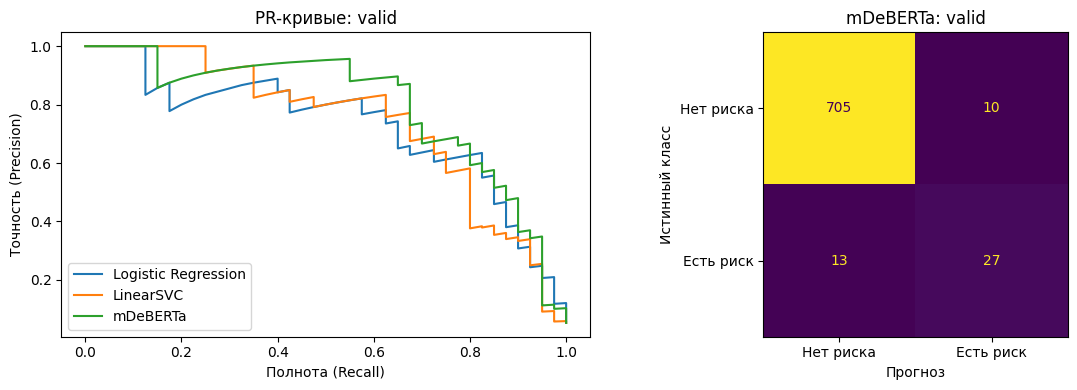

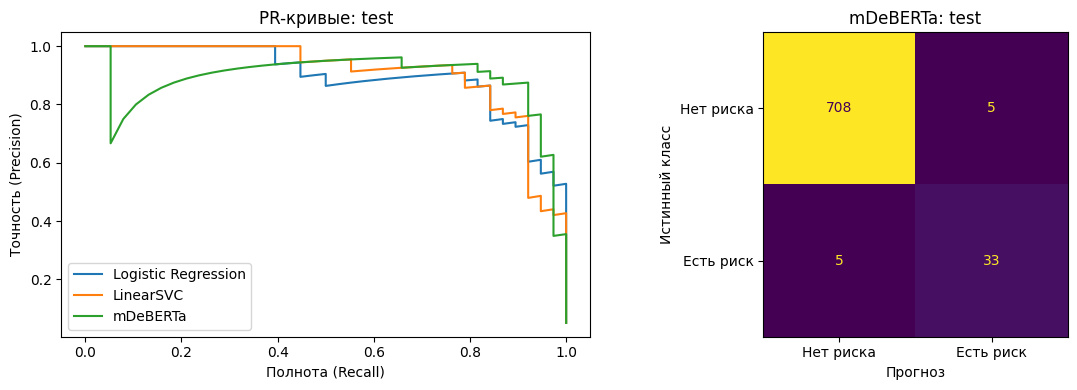

,name,target_precision,status
0,binary_LogisticRegression,0.8,insufficient_calibration_support
1,binary_LogisticRegression,0.9,insufficient_calibration_support
2,binary_LinearSVC,0.8,insufficient_calibration_support
3,binary_LinearSVC,0.9,insufficient_calibration_support
4,binary_mdeberta_text_seed42,0.8,insufficient_calibration_support
5,binary_mdeberta_text_seed42,0.9,insufficient_calibration_support


In [20]:
monitor_rows, operating_interval_tables = [], []
for split in ['valid', 'test']:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for family, name in [('Logistic Regression', 'binary_LogisticRegression'), ('LinearSVC', 'binary_LinearSVC'), ('mDeBERTa', main_binary['name'])]:
        frame = evaluated[(name, split)]
        p, r, thresholds = precision_recall_curve(frame.y, frame.score)
        axes[0].plot(r, p, label=family)
        save_csv(f'monitoring/pr_{name}_{split}.csv', pd.DataFrame({'precision':p, 'recall':r, 'threshold':np.r_[thresholds, np.nan]}))
    axes[0].set(xlabel='Полнота (Recall)', ylabel='Точность (Precision)', title=f'PR-кривые: {split}')
    axes[0].legend()
    chosen = evaluated[(main_binary['name'], split)]
    ConfusionMatrixDisplay.from_predictions(chosen.y, chosen.pred, labels=[0,1],
        display_labels=['Нет риска','Есть риск'], colorbar=False, ax=axes[1])
    axes[1].set(title=f'mDeBERTa: {split}', xlabel='Прогноз', ylabel='Истинный класс')
    save_fig(f'pr_cm_{split}.png')
    for task, main in [('binary', main_binary), ('multiclass', main_multi)]:
        for name in [task+'_LogisticRegression', main['name']]:
            frame = evaluated[(name, split)]
            cm = confusion_matrix(frame.y, frame.pred, labels=[0,1] if task=='binary' else range(4))
            save_csv(f'metrics/confusion_{name}_{split}.csv', pd.DataFrame(cm).rename_axis('true_class').reset_index())
for name in ['binary_LogisticRegression', 'binary_LinearSVC', main_binary['name']]:
    cal = evaluated[(name, 'calibration')]
    p, r, ts = precision_recall_curve(cal.y, cal.score)
    for target in PRECISION_TARGETS:
        candidates = [(r[i], float(t)) for i,t in enumerate(ts) if p[i] >= target and int(cal.score.ge(t).sum()) >= MIN_ALERTS]
        threshold = max(candidates, default=None)
        if threshold is None:
            monitor_rows.append(dict(name=name, target_precision=target, status='insufficient_calibration_support'))
            continue
        t = threshold[1]
        for split in ['calibration', 'valid', 'test']:
            frame = evaluated[(name, split)]
            values = binary_values(frame.y.to_numpy(), frame.score.ge(t).to_numpy(dtype=int), frame.score.to_numpy())
            monitor_rows.append(dict(name=name, target_precision=target, threshold=t, split=split,
                status='estimated_no_guarantee', alerts=int(frame.score.ge(t).sum()), **values))
            fixed = frame.copy(); fixed['pred'] = fixed.score.ge(t).astype(int)
            fixed.attrs['model'] = name
            operating_ci = cluster_intervals(fixed, fixed, 'binary', n_boot=BOOTSTRAP_REPS, seed=SEED)
            operating_ci = operating_ci[operating_ci.model.eq(name)].drop_duplicates(['model', 'metric']).copy()
            operating_ci['split'] = split; operating_ci['target_precision'] = target; operating_ci['threshold'] = t
            operating_interval_tables.append(operating_ci)
monitoring = pd.DataFrame(monitor_rows)
save_csv('monitoring/precision_targets.csv', monitoring)
if operating_interval_tables:
    save_csv('monitoring/precision_target_intervals.csv', pd.concat(operating_interval_tables, ignore_index=True))
display(monitoring)


## 14. Анализ ошибок

Рассматриваются реальные ложные предупреждения, пропущенные риски, общие ошибки и случаи, где верна только одна модель. Отдельно показаны различия между `text` и `text_without_title` на допустимом подмножестве. Фрагменты входа помогают проверить гипотезы о недостатке контекста и неоднозначности; возможная причина отделяется от наблюдаемой ошибки.


In [21]:
error_tables = []
for split in ['valid', 'test']:
    lr = evaluated[('binary_LogisticRegression', split)]
    dl = evaluated[(main_binary['name'], split)]
    paired = lr[['sample_id','y','pred','score']].rename(columns={'pred':'lr_pred','score':'lr_score'}).merge(
        dl[['sample_id','pred','score']].rename(columns={'pred':'dl_pred','score':'dl_score'}), on='sample_id', validate='one_to_one')
    paired = paired.merge(parts[split][['sample_id','event_group_id','risk_type_4cls','title','text_fragment']], on='sample_id', validate='one_to_one')
    lr_bad = paired.lr_pred.ne(paired.y); dl_bad = paired.dl_pred.ne(paired.y)
    masks = {'dl_false_positive':paired.y.eq(0)&paired.dl_pred.eq(1),
             'dl_false_negative':paired.y.eq(1)&paired.dl_pred.eq(0),
             'lr_false_positive':paired.y.eq(0)&paired.lr_pred.eq(1),
             'lr_false_negative':paired.y.eq(1)&paired.lr_pred.eq(0),
             'both_wrong':lr_bad&dl_bad, 'lr_only_wrong':lr_bad&~dl_bad, 'dl_only_wrong':~lr_bad&dl_bad}
    for category, mask in masks.items():
        table = paired[mask].copy(); table['error_group'] = category; table['split'] = split
        table['excerpt'] = table.text_fragment.str.replace(r'\s+', ' ', regex=True).str.slice(0, 500)
        inputs=parts[split].set_index('sample_id').loc[table.sample_id]
        if selected_mode=='text_without_title': model_inputs=inputs.text_without_title.tolist()
        elif selected_mode=='bank_context':model_inputs=[bank_context(b,t,h) for b,t,h in zip(inputs.entity_norm,inputs.text_fragment,inputs.title)]
        else:model_inputs=inputs.text_fragment.tolist()
        table['dl_input_excerpt']=[text[:500] for text in model_inputs]
        table = table.drop(columns='text_fragment'); table['observed_evidence'] = ''; table['interpretation_to_check'] = ''
        error_tables.append(table)
        print(split, category, ':',len(table))
        display(table[['sample_id','risk_type_4cls','title','excerpt','dl_input_excerpt','lr_pred','dl_pred']].head(3))
save_csv('errors/binary_error_examples.csv', pd.concat(error_tables, ignore_index=True))


title_disagreements=[]
for split in ['valid','test']:
    ids=parts[split].loc[parts[split].title_eligible,'sample_id']
    text_name=next(r['name'] for r in dl_binary if r['mode']=='text' and r['seed']==42)
    removed_name=next(r['name'] for r in dl_binary if r['mode']=='text_without_title' and r['seed']==42)
    left=evaluated[(text_name,split)].set_index('sample_id').loc[ids]
    right=evaluated[(removed_name,split)].set_index('sample_id').loc[ids]
    table=parts[split].set_index('sample_id').loc[ids,['title','risk_type_4cls','text_fragment','text_without_title']].copy()
    table['text_pred']=left.pred;table['without_title_pred']=right.pred;table['y']=left.y
    table=table[table.text_pred.ne(table.without_title_pred)].copy()
    table['text_correct']=table.text_pred.eq(table.y);table['without_title_correct']=table.without_title_pred.eq(table.y)
    table['split']=split
    for column in ['text_fragment','text_without_title']:table[column]=table[column].str.slice(0,500)
    table=table.reset_index();title_disagreements.append(table)
    print('Различия прогнозов text / text_without_title:',split,len(table))
    display(table.head(5))
save_csv('errors/title_ablation_disagreements.csv',pd.concat(title_disagreements,ignore_index=True))


valid dl_false_positive : 10


,sample_id,risk_type_4cls,title,excerpt,dl_input_excerpt,lr_pred,dl_pred
23,ml_nat5_final_000197,no_risk,Следствие вернулось к делу о хищении из бюджет...,Следствие вернулось к делу о хищении из бюджет...,Следствие вернулось к делу о хищении из бюджет...,0,1
39,ml_nat5_final_000282,no_risk,СМИ сообщили о возможном расширении обвинения ...,СМИ сообщили о возможном расширении обвинения ...,СМИ сообщили о возможном расширении обвинения ...,0,1
52,ml_nat5_final_000366,no_risk,Работа Сбербанка восстановлена после массового...,Работа Сбербанка восстановлена после массового...,Работа Сбербанка восстановлена после массового...,1,1


valid dl_false_negative : 13


,sample_id,risk_type_4cls,title,excerpt,dl_input_excerpt,lr_pred,dl_pred
16,ml_nat5_final_000101,regulatory_risk,Порошенко призвали запретить работу российских...,Порошенко призвали запретить работу российских...,Порошенко призвали запретить работу российских...,0,0
24,ml_nat5_final_000202,regulatory_risk,Дворкович: власти договариваются с Китаем о фи...,Дворкович: власти договариваются с Китаем о фи...,Дворкович: власти договариваются с Китаем о фи...,0,0
28,ml_nat5_final_000237,operational_risk,Глава Сбербанка отчитался о «косяках»,Глава Сбербанка отчитался о «косяках» Он подче...,Глава Сбербанка отчитался о «косяках» Он подче...,0,0


valid lr_false_positive : 16


,sample_id,risk_type_4cls,title,excerpt,dl_input_excerpt,lr_pred,dl_pred
19,ml_nat5_final_000135,no_risk,Изображают жертву: Мошенники изобрели новый сп...,Изображают жертву: Мошенники изобрели новый сп...,Изображают жертву: Мошенники изобрели новый сп...,1,0
20,ml_nat5_final_000138,no_risk,Российские банки запустят идентификацию клиент...,Российские банки запустят идентификацию клиент...,Российские банки запустят идентификацию клиент...,1,0
29,ml_nat5_final_000239,no_risk,Райффайзенбанк сообщил об устранении неполадок...,Райффайзенбанк сообщил об устранении неполадок...,Райффайзенбанк сообщил об устранении неполадок...,1,0


... (22 outputs left out)

Различия прогнозов text / text_without_title: valid 20


,sample_id,title,risk_type_4cls,text_fragment,text_without_title,text_pred,without_title_pred,y,text_correct,without_title_correct,split
0,ml_nat5_final_000138,Российские банки запустят идентификацию клиент...,no_risk,Российские банки запустят идентификацию клиент...,"Они не исключают, что мошенники смогут подобра...",0,1,0,True,False,valid
1,ml_nat5_final_000197,Следствие вернулось к делу о хищении из бюджет...,no_risk,Следствие вернулось к делу о хищении из бюджет...,Дело в отношении начальника отдела финансирова...,1,0,0,False,True,valid
2,ml_nat5_final_000236,Европейский суд общей юрисдикции подтвердил по...,no_risk,Европейский суд общей юрисдикции подтвердил по...,Европейский суд общей юрисдикции зарегистриров...,0,1,0,True,False,valid
3,ml_nat5_final_000310,Сбербанк объявил о новом компьютерном сбое,no_risk,Сбербанк объявил о новом компьютерном сбое Зая...,Заявки инвесторов на ММВБ с 9:30 по московском...,0,1,0,True,False,valid
4,ml_nat5_final_000321,Сбербанк откажется от авторизации клиентских о...,no_risk,Сбербанк откажется от авторизации клиентских о...,Сбербанк в случае технических сбоев будет пров...,0,1,0,True,False,valid


Различия прогнозов text / text_without_title: test 18


,sample_id,title,risk_type_4cls,text_fragment,text_without_title,text_pred,without_title_pred,y,text_correct,without_title_correct,split
0,ml_nat5_final_000045,Red Wings выложила паспортные данные пассажиро...,cyber_risk,Red Wings выложила паспортные данные пассажиро...,"Там и мои данные с данными моего ребёнка есть,...",1,0,1,True,False,test
1,ml_nat5_final_000088,"В работе сервиса ""Сбербанк Онлайн"" произошел сбой",operational_risk,"В работе сервиса ""Сбербанк Онлайн"" произошел с...","МОСКВА, 10 апреля. /ТАСС/.",1,0,1,True,False,test
2,ml_nat5_final_000116,"Сбой в работе сервиса ""Сбербанк онлайн"" устранен",operational_risk,"Сбой в работе сервиса ""Сбербанк онлайн"" устран...","МОСКВА, 26 октября. /ТАСС/.",1,0,1,True,False,test
3,ml_nat5_final_000185,ФСБ Петербурга увидела умышленное неисполнение...,no_risk,ФСБ Петербурга увидела умышленное неисполнение...,"По данным «Фонтанки», уголовное дело возбужден...",1,0,0,False,True,test
4,ml_nat5_final_000288,Связанная с Батуриной компания перестала плати...,no_risk,Связанная с Батуриной компания перестала плати...,"Кредит, выданный ""Премьер-эстейт"", стал поводо...",0,1,0,True,False,test


## 15. Выводы и ограничения

Выводы учитывают качество, интервалы, устойчивость, FP/FN и время обучения. Интервалы относятся к фиксированным моделям и не охватывают весь поиск конфигураций. Частичная обработка заголовков оценивается отдельно на всей выборке и на общем допустимом подмножестве.

В test всего 38 рисковых новостей, включая четыре регуляторных: уверенные выводы о редком классе невозможны. Дисбаланс и повторы текстов ограничивают обобщение. Исходная тестовая выборка уже использовалась в предварительных экспериментах, поэтому не является полностью независимым подтверждением качества.


In [22]:
lines = ['### Результаты нового запуска']
for task, metric in [('binary','f1'), ('multiclass','macro_f1')]:
    for split in ['valid','test']:
        row = intervals[(intervals.task==task)&(intervals.split==split)&(intervals.model=='delta')&(intervals.metric==metric)].iloc[0]
        available = np.isfinite([row.lower, row.upper]).all() and row.valid_replicates >= .9*BOOTSTRAP_REPS
        crossing = row.lower <= 0 <= row.upper
        evidence = ('интервал недостаточно определён; вывод о преимуществе не делается' if not available else
                    'направление преимущества не подтверждено' if crossing else
                    'интервал не включает ноль; вывод условен на фиксированных моделях и этом наборе')
        lines.append(f"- {task}, {split}: разница mDeBERTa − LR по {metric} = {row.estimate:.4f}, "
                     f"95% ДИ [{row.lower:.4f}; {row.upper:.4f}]; {evidence}.")
for task, main in [('binary', main_binary), ('multiclass', main_multi)]:
    subset = metrics[metrics.split.eq('valid') & metrics.name.isin([
        r['name'] for r in dl_records if r['task']==task and (task!='binary' or r['mode']==selected_mode)])]
    key = 'f1' if task=='binary' else 'macro_f1'
    lines.append(f"- {task}: диапазон valid {key} по выполненным seed: {subset[key].min():.4f}–{subset[key].max():.4f}; число seed: {len(subset)}.")
for mode in ['text_without_title','bank_context']:
    delta = ablation_intervals[(ablation_intervals.comparison==mode+' minus text') & ablation_intervals.metric.eq('f1') & ablation_intervals.split.eq('valid')]
    values = ', '.join(f"seed {int(r.seed)}: {r.estimate:+.4f} [{r.lower:+.4f}; {r.upper:+.4f}]" for r in delta.itertuples())
    direction = ('точечный F1 выше для всех выполненных seed' if delta.estimate.gt(0).all() else
                 'точечный F1 ниже для всех выполненных seed' if delta.estimate.lt(0).all() else
                 'единого положительного направления эффекта по seed нет')
    uncertainty = ('все интервалы выше нуля' if delta.lower.gt(0).all() else
                   'интервалы не подтверждают положительный эффект во всех выполненных seed')
    lines.append(f'- Абляция на общем допустимом подмножестве {mode} − text, valid F1: {values}; {direction}; {uncertainty}. '
                 'Практический размер эффекта и устойчивость требуют отдельной оценки; сравнения исследовательские.')
lines.extend(['- Precision и Recall оцениваются совместно с абсолютными FP/FN. Практический выбор требует стоимости ошибок и бюджета аналитиков.',
    '- Время обучения сохранено для каждого запуска. Применение DL требует оправданного эффекта качества или контекста с учётом GPU-затрат и устойчивости.',
    '- Нет нового независимого test. Повторы текстов, малые редкие классы и возможный сдвиг банков/периодов ограничивают перенос результатов.'])
if PROFILE=='CORE': lines.append('- CORE: устойчивость по трём seed не проверена.')
lines.append(f'- Удаление заголовка выполнено для {int(df.title_eligible.sum())} из {len(df)} текстов; остальные сохранены без изменений. Общие метрики оценивают частичную политику, строгая абляция — только допустимое подмножество.')
conclusion = '\n'.join(lines)
display(Markdown(conclusion))
(OUTPUT/'conclusion.md').write_text(conclusion, encoding='utf-8')
save_json('summary.json', dict(protocol=protocol, decisions=decisions, environment=ENVIRONMENT,
    experiments=records, metrics=metrics.to_dict('records'), intervals=intervals.to_dict('records'),
    seed_experiments=seed_rows, strict_ablation=strict_ablation.to_dict('records'), ablation_intervals=ablation_intervals.to_dict('records'), title_policy=TITLE_POLICY, title_audit_sha256=TITLE_AUDIT_SHA, completed_dl_trainings=len(dl_records),
    planned_dl_trainings=12 if PROFILE=='FULL' else 4,
    skipped=[] if PROFILE=='FULL' else ['binary seeds 123/2026', 'multiclass seeds 123/2026'],
    independent_new_test=False, conclusion=conclusion))
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() == DATA_SHA
save_json('experiment_status.json', dict(status='complete', experiment_sha256=EXPERIMENT_SHA,
    completed_dl_trainings=len(dl_records), summary_sha256=hashlib.sha256((OUTPUT/'summary.json').read_bytes()).hexdigest()))
print('Результаты сохранены:', OUTPUT)


### Результаты нового запуска
- binary, valid: разница mDeBERTa − LR по f1 = 0.0346, 95% ДИ [-0.0783; 0.1469]; направление преимущества не подтверждено.
- binary, test: разница mDeBERTa − LR по f1 = 0.0730, 95% ДИ [-0.0281; 0.1880]; направление преимущества не подтверждено.
- multiclass, valid: разница mDeBERTa − LR по macro_f1 = -0.1466, 95% ДИ [-0.2620; 0.0422]; направление преимущества не подтверждено.
- multiclass, test: разница mDeBERTa − LR по macro_f1 = -0.1960, 95% ДИ [-0.3183; -0.0627]; интервал не включает ноль; вывод условен на фиксированных моделях и этом наборе.
- binary: диапазон valid f1 по выполненным seed: 0.6593–0.7013; число seed: 3.
- multiclass: диапазон valid macro_f1 по выполненным seed: 0.2432–0.6083; число seed: 3.
- Абляция на общем допустимом подмножестве text_without_title − text, valid F1: seed 42: -0.0748 [-0.1776; +0.0278], seed 123: +0.0080 [-0.1065; +0.1238], seed 2026: -0.0489 [-0.1426; +0.0437]; единого положительного направления эффекта по seed нет; интервалы не подтверждают положительный эффект во всех выполненных seed. Практический размер эффекта и устойчивость требуют отдельной оценки; сравнения исследовательские.
- Абляция на общем допустимом подмножестве bank_context − text, valid F1: seed 42: -0.0346 [-0.1485; +0.0957], seed 123: +0.0202 [-0.0479; +0.0994], seed 2026: +0.0349 [-0.0455; +0.1106]; единого положительного направления эффекта по seed нет; интервалы не подтверждают положительный эффект во всех выполненных seed. Практический размер эффекта и устойчивость требуют отдельной оценки; сравнения исследовательские.
- Precision и Recall оцениваются совместно с абсолютными FP/FN. Практический выбор требует стоимости ошибок и бюджета аналитиков.
- Время обучения сохранено для каждого запуска. Применение DL требует оправданного эффекта качества или контекста с учётом GPU-затрат и устойчивости.
- Нет нового независимого test. Повторы текстов, малые редкие классы и возможный сдвиг банков/периодов ограничивают перенос результатов.
- Удаление заголовка выполнено для 4926 из 5041 текстов; остальные сохранены без изменений. Общие метрики оценивают частичную политику, строгая абляция — только допустимое подмножество.

Результаты сохранены: /kaggle/working/bank_risk_diploma_final


### Итоговые выводы

Среди трёх основных бинарных моделей mDeBERTa с полным текстом и seed 42 получила наибольший наблюдаемый test F1: 0,8684 против 0,8533 у LinearSVC и 0,7955 у Logistic Regression. Однако Logistic Regression обнаружила больше рисковых новостей — 35 из 38, создав 15 ложных предупреждений. mDeBERTa обнаружила 33 риска при пяти ложных предупреждениях, LinearSVC — 32 при тех же пяти. Это разные рабочие профили: Recall важна для сокращения пропусков, Precision — для снижения нагрузки на аналитиков. По test AP среди этих моделей лидировала LinearSVC.

Парные 95%-е интервалы разности F1 mDeBERTa и Logistic Regression включают ноль на valid и test. Поэтому статистически подтверждённого бинарного превосходства нейросети нет. Небольшой отрыв от LinearSVC также не позволяет объявлять mDeBERTa однозначно лучшей: отдельный парный интервал для этой пары не представлен.

В многоклассовой задаче Logistic Regression получила test Macro F1 0,7973, LinearSVC — 0,6445, mDeBERTa — 0,6013. На test Logistic Regression лучше распознавала киберриск и операционный риск. Для `regulatory_risk` F1 нейросети и LinearSVC равен нулю, у Logistic Regression — 0,4; четырёх тестовых примеров недостаточно для надёжной оценки. Хорошее распознавание преобладающего `no_risk` не компенсирует слабое качество редких категорий в Macro F1. Парный интервал на test поддерживает преимущество Logistic Regression над mDeBERTa для этой выборки; на valid направление различия не подтверждено.

Абляция указывает на полезность заголовка. На общем надёжно обработанном подмножестве полный текст имел более высокую AP во всех трёх seed на valid и test. По F1 он выигрывал в двух из трёх запусков на valid и во всех на test, но на test интервал подтвердил направление только для seed 42. На valid полученные интервалы разности F1 между входами включали ноль: устойчивое преимущество не подтверждено. Банковский контекст не дал устойчивого улучшения: результат зависел от seed и метрики. Полный текст выбран по stop, основной seed 42 задан заранее; test не использовался для выбора. Неоднозначные заголовки оставались неизменными. Общие метрики описывают частичную обработку, строгая абляция — общее надёжно обработанное подмножество.

Устойчивость двух задач заметно различалась. При seed 42, 123 и 2026 valid F1 бинарной модели с полным текстом менялся от 0,6593 до 0,7013, а многоклассовый Macro F1 — от 0,2432 до 0,6083. При seed 123 многоклассовая модель имела нулевой F1 для всех типов риска. Поэтому один удачный запуск не гарантирует надёжного определения категории. Примеры ошибок показывают важность контекста, но не устанавливают причины всех ошибок.

mDeBERTa может быть оправдана в бинарном мониторинге, если выигрыш подтвердится на новых данных и компенсирует вычислительные затраты. Пока LinearSVC остаётся сильной альтернативой, а Logistic Regression полезна при высокой цене пропуска риска и выглядит предпочтительнее для многоклассовой задачи. Классические модели обучались за секунды, нейросеть требовала GPU и значительно большего времени. Скорость работы моделей в промышленной системе отдельно не оценивалась.

Надёжность и перенос результатов ограничены малым числом рисковых новостей, редкими классами, дисбалансом, повторами текстов и статистической неопределённостью. Тестовая выборка уже использовалась в предварительных экспериментах и не даёт полностью независимого подтверждения. Для новых новостей, банков и периодов нужна независимая размеченная выборка.
